# R-KalWeNN no YearPredictionMSD

Mesmo modelo e mesmas definições do notebook 06, aplicados ao
YearPredictionMSD. As diferenças em relação ao House Prices estão todas na
seção 1 e na seção 3.

| seção | conteúdo |
|---|---|
| 1 | configuração |
| 2 | definições: thermometer, médias, endereçamento, ReW, R-KalWeNN |
| 3 | dados: carga, divisão do UCI e análise |
| 4 | R-KalWeNN: `c`, `y` e a atualização de cada um |
| 5 | avaliação vetorizada |
| 6 | grid search |
| 7 | a ReW na configuração vencedora |
| 8 | endereços ocupados por RAM node |
| 9 | resultado |

**Três diferenças em relação ao notebook 06.** O baseline publicado não é a
tese do Lusquino, que cobre `calcofi`, `houseprice`, `kdd` e `parkison` e não
este dataset, e sim o artigo que apresentou o Million Song Dataset, cuja tabela
5 traz quatro métodos sobre exatamente esta divisão (ver seção 3.6). O alvo é o
ano de lançamento e não passa por `log1p`. E a divisão de treino e teste é a
prescrita pelo UCI, descrita na seção 3.2, e não um `train_test_split`
embaralhado.

---
# Seção 1 — Configuração

In [62]:
import os
import time
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import product
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": .25,
    "axes.spines.top": False, "axes.spines.right": False,
})
COR_KAL, COR_REW, COR_REF = "#2F6B6A", "#B4674D", "#8A8F98"

# ── dados ────────────────────────────────────────────────────────────────────
URL_UCI   = "https://archive.ics.uci.edu/static/public/203/yearpredictionmsd.zip"
URL_ALT   = ("https://archive.ics.uci.edu/ml/machine-learning-databases/"
             "00203/YearPredictionMSD.txt.zip")
ARQ_ZIP   = "YearPredictionMSD.zip"
ARQ_TXT   = "YearPredictionMSD.txt"

# Divisão prescrita pelo UCI, ver seção 3.2. NÃO é embaralhada.
N_TREINO_UCI = 463715
N_TESTE_UCI  = 51630

# O tamanho de treino e de teste NÃO é definido aqui. Ele fica na célula da
# seção 3.2, junto da divisão que o consome.

# ── codificação ──────────────────────────────────────────────────────────────
SEED_MAPPING = 0

print(f"UCI: {N_TREINO_UCI:,} treino + {N_TESTE_UCI:,} teste = "
      f"{N_TREINO_UCI + N_TESTE_UCI:,} exemplos, 90 atributos")


UCI: 463,715 treino + 51,630 teste = 515,345 exemplos, 90 atributos


---
# Seção 2 — Definições

## 2.1 Codificação: thermometer simples

É o `ThermometerEncoder` do projeto de classificação, em
`KalWeNN/wisard/encoder.py`, e não o `DynamicThermometer` do `wisardpkg` que o
notebook 06 usa.

O valor é primeiro **cortado** na faixa $[\min, \max]$ do treino, depois
convertido num nível inteiro

$$
k = \left\lfloor \frac{x - \min}{\max - \min + \varepsilon}\, n \right\rfloor,
\qquad k \in [0, n]
$$

e os $k$ primeiros bits são ligados. Assim $x = \min$ dá o vetor todo zero e
$x = \max$ dá o vetor todo um.

Duas diferenças em relação ao `DynamicThermometer`. Este **corta** valores fora
da faixa do treino, em vez de deixá-los saturar por conta própria, o que importa
porque o teste pode ter valores fora do intervalo visto no treino. E a
comparação é por nível inteiro e não por limiar com `>` estrito, o que muda o
tratamento das bordas.

In [63]:
class ThermometerEncoder:
    """Porte do encoder do projeto de classificação (KalWeNN/wisard/encoder.py)."""

    def __init__(self, minimum, maximum, resolution):
        self.minimum, self.maximum, self.resolution = minimum, maximum, resolution
        self._range = (maximum - minimum) + 1e-9

    def encode(self, column):
        col = np.clip(column, self.minimum, self.maximum)
        k = np.clip(((col - self.minimum) / self._range * self.resolution).astype(int),
                    0, self.resolution)
        return (np.arange(self.resolution) < k[:, np.newaxis]).astype(np.uint8)


def build_encoders(X, resolution):
    mins, maxs = X.min(axis=0), X.max(axis=0)
    return [ThermometerEncoder(mins[j], maxs[j], resolution) for j in range(X.shape[1])]


def apply_encoders(X, encoders):
    return np.concatenate([enc.encode(X[:, j]) for j, enc in enumerate(encoders)], axis=1)


print("ThermometerEncoder definido")

ThermometerEncoder definido


---
## 2.2 As médias

Duas famílias, porque as duas células guardam coisas diferentes.

**Família ReW.** A célula guarda contador $c_k$ e soma $S_k$. A estimativa da
RAM node é $\mu_k = S_k / c_k$, e o contador entra como **denominador**.

| média | fórmula |
|---|---|
| `SimpleMean` | $\sum_k S_k \big/ \sum_k c_k$ |
| `PowerMean(p)` | $\left(\frac{1}{m}\sum \mu_k^{\,p}\right)^{1/p}$ |
| `HarmonicMean` | $m \big/ \sum \mu_k^{-1}$ |
| `HarmonicPower(p)` | $\left(m \big/ \sum \mu_k^{-p}\right)^{1/p}$ |
| `ExponentialMean` | $\log\!\left(\frac{1 + \sum e^{\mu_k}}{m}\right)$ |
| `Median` | valor central dos $\mu_k$, pela fórmula da tese |

$m$ é o número de RAM nodes com $c_k \neq 0$. O `1 +` da `ExponentialMean` está
no código da referência (`double emean = 1`) e é mantido. A `Median` é o porte
do `Median::calculate` do `wisardpkg`, que é o que a tese executou.

**Família R-KalWeNN.** A célula guarda uma confiança $c_k \in [0,1)$ e um valor
esperado $y_k$. O $y_k$ já é a estimativa local, então não há divisão por
contador: o $c_k$ **multiplica** o $y_k$, e a normalização é $\sum c_k$.

O prefixo `K` marca que são as fórmulas ponderadas que desenhamos para o
R-KalWeNN, e não as da Regression WiSARD.

| média | fórmula |
|---|---|
| `K-SimpleMean` | $\dfrac{\sum c_k y_k}{\sum c_k}$ |
| `K-PowerMean(p)` | $\left(\dfrac{\sum c_k y_k^{\,p}}{\sum c_k}\right)^{1/p}$ |
| `K-HarmonicMean` | $\dfrac{\sum c_k}{\sum c_k / y_k}$ |
| `K-HarmonicPower(p)` | $\left(\dfrac{\sum c_k}{\sum c_k / y_k^{\,p}}\right)^{1/p}$ |
| `K-ExponentialMean` | $\log\!\left(\dfrac{\sum c_k e^{y_k}}{\sum c_k}\right)$ |
| `K-Median` | $y$ onde o $c$ acumulado cruza $\tfrac{1}{2}\sum c_k$ |

Onde a ReW divide por $c_k$, aqui multiplica. O $\sum c_k$ no denominador é o
que impede o resultado de encolher: sem ele, multiplicar por $c_k < 1$ puxaria
a predição para baixo do valor esperado.

Duas diferenças deliberadas em relação à família ReW. Só entram células com
evidência, em vez de passar $[0,0]$ e cada média filtrar. E o `1 +` da
exponencial foi retirado, porque não tem lugar numa forma normalizada por
$\sum c_k$.

`GeometricMean` e `LogisticMean` ficaram de fora das duas famílias. A geométrica
acumula um produto de $\mu_k \approx 12$ sobre as RAM nodes e estoura o `double`
com mais de 285 delas; a logística devolve sempre um valor em $(0,1)$, e o alvo
vale 12.

Harmônica e harmônica-potência exigem $y_k > 0$. Com o alvo em `log1p` isso
vale sempre, e a condição está escrita no código.

In [64]:
# ─────────────────────────── família ReW ─────────────────────────────────────
class Mean:
    """`output_rams` é uma lista de [contador, soma_y], incluindo as RAM nodes
    não visitadas como [0, 0], como no predict da referência."""
    nome = "Mean"
    def calculate(self, output_rams):
        raise NotImplementedError
    def __repr__(self):
        return f"ReW.{self.nome}"


class SimpleMean(Mean):
    nome = "SimpleMean"
    def calculate(self, output_rams):
        sc = sum(c for c, _ in output_rams)
        sy = sum(y for _, y in output_rams)
        return sy / sc if sc > 0 else 0.0


class PowerMean(Mean):
    def __init__(self, power=2):
        self.power = power; self.nome = f"PowerMean({power})"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                s += (y / c) ** self.power; m += 1
        return (s / m) ** (1.0 / self.power) if m > 0 else 0.0


class HarmonicMean(Mean):
    nome = "HarmonicMean"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                mu = y / c
                if mu != 0:
                    s += 1.0 / mu; m += 1
        return m / s if m > 0 else 0.0


class HarmonicPowerMean(Mean):
    def __init__(self, power=2):
        self.power = power; self.nome = f"HarmonicPower({power})"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                mu = y / c
                if mu != 0:
                    s += 1.0 / (mu ** self.power); m += 1
        return (m / s) ** (1.0 / self.power) if m > 0 else 0.0


class ExponentialMean(Mean):
    """log((1 + soma de e^mu) / m), com o `1 +` da referência preservado.

    Calculada de forma estável: com mu na escala do ano, e^2000 é `inf` em
    float64, cujo limite é e^709. Pondo mx = max(mu),

        log((1 + soma e^mu)/m) = mx + log(e^-mx + soma e^(mu-mx)) - log(m)

    que é a mesma expressão e não estoura. Confere com a forma direta até o
    último bit onde a forma direta ainda funciona.
    """
    nome = "ExponentialMean"
    def calculate(self, output_rams):
        mus = [y / c for c, y in output_rams if c != 0]
        if not mus:
            return 0.0
        mus = np.asarray(mus, dtype=float); mx = mus.max()
        return float(mx + np.log(np.exp(-mx) + np.exp(mus - mx).sum())
                     - np.log(len(mus)))


class Median(Mean):
    """Porte do Median::calculate do wisardpkg, que é o que a tese executou.

    Divide sem checar contador zero, ao contrário das outras médias, e usa
    índice deslocado em um. Onde a referência leria fora do vetor, aqui devolve
    NaN em vez de ler lixo de memória, e os NaN vão para o fim da ordenação.
    """
    nome = "Median"
    def calculate(self, output_rams):
        mus = [np.divide(float(y), float(c)) if c != 0 else float("nan")
               for c, y in output_rams]
        mus = sorted(mus, key=lambda v: (np.isnan(v), v))
        n = len(mus)
        if n % 2 == 0:
            i = n // 2
            return (mus[i] + mus[i + 1]) / 2.0 if i + 1 < n else float("nan")
        i = (n - 1) // 2 + 1
        return mus[i] if i < n else float("nan")


def medias_rew():
    return {"SimpleMean": SimpleMean(), "PowerMean(2)": PowerMean(2),
            "HarmonicMean": HarmonicMean(), "HarmonicPower(2)": HarmonicPowerMean(2),
            "ExponentialMean": ExponentialMean(), "Median": Median()}


print("médias da família ReW:", ", ".join(medias_rew()))

médias da família ReW: SimpleMean, PowerMean(2), HarmonicMean, HarmonicPower(2), ExponentialMean, Median


In [65]:
# ────────────────────── família R-KalWeNN (ponderadas) ───────────────────────
class MediaK:
    """`pares` é uma lista de (c_k, y_k) das células COM evidência.

    c_k é confiança em [0,1), y_k é o valor esperado local.
    Todas normalizam por sum(c), o que mantém o resultado na escala do alvo.
    """
    nome = "MediaK"
    def calculate(self, pares):
        raise NotImplementedError
    def __repr__(self):
        return self.nome


class KSimpleMean(MediaK):
    nome = "K-SimpleMean"
    def calculate(self, pares):
        sc = sum(c for c, _ in pares)
        return sum(c * y for c, y in pares) / sc if sc > 0 else np.nan


class KPowerMean(MediaK):
    def __init__(self, power=2):
        self.power = power; self.nome = f"K-PowerMean({power})"
    def calculate(self, pares):
        sc = sum(c for c, _ in pares)
        if sc <= 0:
            return np.nan
        return (sum(c * y ** self.power for c, y in pares) / sc) ** (1.0 / self.power)


class KHarmonicMean(MediaK):
    nome = "K-HarmonicMean"
    def calculate(self, pares):
        sc = s = 0.0
        for c, y in pares:
            if y > 0:
                sc += c; s += c / y
        return sc / s if s > 0 else np.nan


class KHarmonicPowerMean(MediaK):
    def __init__(self, power=2):
        self.power = power; self.nome = f"K-HarmonicPower({power})"
    def calculate(self, pares):
        sc = s = 0.0
        for c, y in pares:
            if y > 0:
                sc += c; s += c / y ** self.power
        return (sc / s) ** (1.0 / self.power) if s > 0 else np.nan


class KExponentialMean(MediaK):
    """log(soma c e^y / soma c), calculada de forma estável.

    Pondo mx = max(y), vira mx + log(soma c e^(y-mx) / soma c), que é a mesma
    expressão e não estoura quando y está na escala do ano.
    """
    nome = "K-ExponentialMean"
    def calculate(self, pares):
        sc = sum(c for c, _ in pares)
        if sc <= 0:
            return np.nan
        mx = max(y for _, y in pares)
        return float(mx + np.log(sum(c * np.exp(y - mx) for c, y in pares) / sc))


class KMedian(MediaK):
    """Mediana ponderada: y onde o c acumulado cruza metade de sum(c)."""
    nome = "K-Median"
    def calculate(self, pares):
        pares = sorted(pares, key=lambda t: t[1])
        total = sum(c for c, _ in pares)
        if total <= 0:
            return np.nan
        meio, acum = total / 2.0, 0.0
        for c, y in pares:
            acum += c
            if acum >= meio:
                return y
        return pares[-1][1]


def medias_kal():
    """Prefixo K: fórmulas ponderadas, desenhadas para o R-KalWeNN.

    Não são as da Regression WiSARD, que estão em `medias_rew()`."""
    return {"K-SimpleMean": KSimpleMean(), "K-PowerMean(2)": KPowerMean(2),
            "K-HarmonicMean": KHarmonicMean(),
            "K-HarmonicPower(2)": KHarmonicPowerMean(2),
            "K-ExponentialMean": KExponentialMean(), "K-Median": KMedian()}


print("médias da família R-KalWeNN:", ", ".join(medias_kal()))

médias da família R-KalWeNN: K-SimpleMean, K-PowerMean(2), K-HarmonicMean, K-HarmonicPower(2), K-ExponentialMean, K-Median


---
## 2.2 Endereçamento

In [66]:
class Retina:
    """Converte entrada binarizada em endereços, um por RAM node."""

    def __init__(self, address_size, mapping):
        self.address_size = int(address_size)
        self.mapping = np.asarray(mapping, dtype=int).reshape(-1, self.address_size)
        self.n_rams = self.mapping.shape[0]
        self.n_addr = 1 << self.address_size
        self._pesos = 1 << np.arange(self.address_size)     # LSB primeiro

    def _dtype_addr(self):
        """Menor inteiro que cabe um endereço de `address_size` bits."""
        if self.address_size <= 8:
            return np.uint8
        if self.address_size <= 16:
            return np.uint16
        return np.int64

    def enderecos(self, Xb, bloco=20_000):
        """(n, retina) uint8 -> (n, n_rams).

        Em blocos de linhas: `Xb[:, mapping] * pesos` tem forma
        (n, n_rams, address_size), ou seja n x retina_bits elementos, e num
        único array isso passa de 8 GB com o treino completo. O bloco limita o
        intermediário e o tipo de saída é o menor que cabe o endereço.
        """
        Xb = np.asarray(Xb, dtype=np.uint8)
        dt = self._dtype_addr()
        pesos = self._pesos.astype(dt)
        out = np.empty((len(Xb), self.n_rams), dtype=dt)
        for i in range(0, len(Xb), bloco):
            j = min(i + bloco, len(Xb))
            out[i:j] = (Xb[i:j][:, self.mapping] * pesos).sum(axis=2, dtype=dt)
        return out


def sorteia_mapping(retina_bits, address_size, seed=0):
    """Permutação dos bits da retina, truncada a um múltiplo de address_size."""
    n_rams = retina_bits // address_size
    rng = np.random.default_rng(seed)
    return rng.permutation(retina_bits)[: n_rams * address_size].tolist()


print("Retina definida")

Retina definida


---
## 2.3 Regression WiSARD

Serve de comparação para o R-KalWeNN, com a mesma binarização, o mesmo
`mapping` e a mesma divisão. Cada família de média fica com o seu modelo: a ReW
usa as médias da seção 2.2 sem prefixo, o R-KalWeNN usa as `K-`.

In [67]:
class RegressionWiSARD:
    """Regression WiSARD. Recebe entrada já binarizada."""

    def __init__(self, address_size, mean, mapping):
        self.retina = Retina(address_size, mapping)
        self.mean = mean

    @property
    def n_rams_(self):
        return self.retina.n_rams

    def fit(self, Xb, y):
        y = np.asarray(y, dtype=float)
        addr = self.retina.enderecos(Xb)
        self._mem = [dict() for _ in range(self.n_rams_)]
        for i in range(len(y)):
            for r_ in range(self.n_rams_):
                cel = self._mem[r_].get(addr[i, r_])
                if cel is None:
                    self._mem[r_][addr[i, r_]] = [1.0, y[i]]
                else:
                    cel[0] += 1.0; cel[1] += y[i]
        return self

    def predict(self, Xb):
        addr = self.retina.enderecos(Xb)
        vazia = [0.0, 0.0]
        return np.array([
            self.mean.calculate([self._mem[r_].get(addr[i, r_], vazia)
                                 for r_ in range(self.n_rams_)])
            for i in range(len(addr))])

    def memoria_bytes(self):
        return sum(len(m) for m in self._mem) * 24    # chave + 2 floats


print("RegressionWiSARD definida")

RegressionWiSARD definida


---
# Seção 3 — Dados

## 3.1 Carga

O arquivo tem 515.345 linhas e 91 colunas: a primeira é o ano de lançamento, as
outras 90 são atributos de timbre, sendo 12 médias e 78 covariâncias. São cerca
de 450 MB comprimidos.

A carga usa `float32` nos atributos, o que reduz a memória de 371 MB para 185 MB
e cabe com folga. A resolução do `float32` é de sete dígitos decimais, bem acima
da granularidade que o thermometer usa.

In [68]:
if not os.path.exists(ARQ_TXT):
    if not os.path.exists(ARQ_ZIP):
        print(f"baixando de {URL_UCI} ...")
        try:
            urllib.request.urlretrieve(URL_UCI, ARQ_ZIP)
        except Exception as e:
            print(f"  falhou ({e}), tentando a URL alternativa")
            urllib.request.urlretrieve(URL_ALT, ARQ_ZIP)
    print("descompactando ...")
    with zipfile.ZipFile(ARQ_ZIP) as z:
        nome = [n for n in z.namelist() if n.endswith(".txt")][0]
        with z.open(nome) as origem, open(ARQ_TXT, "wb") as destino:
            destino.write(origem.read())

t0 = time.perf_counter()
dados = pd.read_csv(ARQ_TXT, header=None, dtype=np.float32)
print(f"lido em {time.perf_counter()-t0:.0f} s: {dados.shape[0]:,} linhas x "
      f"{dados.shape[1]} colunas")

y_todos = dados.iloc[:, 0].values.astype(np.float64)     # ano
X_todos = dados.iloc[:, 1:].values                       # 90 atributos
del dados

print(f"alvo (ano): {y_todos.min():.0f} a {y_todos.max():.0f}")
print(f"atributos : {X_todos.shape[1]}, memória {X_todos.nbytes/1e6:.0f} MB")

lido em 17 s: 515,345 linhas x 91 colunas
alvo (ano): 1922 a 2011
atributos : 90, memória 186 MB


## 3.2 Divisão de treino e teste, como o UCI prescreve

A página do dataset no UCI dá uma instrução explícita:

> You should respect the following train / test split: train: first 463,715
> examples, test: last 51,630 examples. It avoids the "producer effect" by
> making sure no song from a given artist ends up in both the train and test
> set.

O motivo é o **efeito produtor**. Músicas do mesmo artista, do mesmo álbum ou
do mesmo produtor compartilham características de timbre que vêm da produção e
não do ano. Se duas faixas do mesmo disco caírem uma no treino e outra no
teste, o modelo acerta o ano por reconhecer o disco, não por aprender a relação
entre timbre e época. O resultado fica otimista e não generaliza.

O arquivo já vem ordenado de forma que essa divisão por posição separa os
artistas. Por isso a divisão é **por posição e sem embaralhar**, ao contrário
do notebook 06, que usa `train_test_split` com `random_state=0`.

Consequência prática para nós: não existe sorteio na divisão, então ela não é
fonte de variação. A única aleatoriedade dos experimentos é o `mapping` e a
ordem de apresentação no treino.

### Modo reduzido

A divisão do UCI é sempre a mesma, e o modo reduzido subamostra **dentro** dela.
O treino reduzido é sorteado entre os 463.715 primeiros exemplos, e o teste
reduzido entre os 51.630 últimos. Nenhum exemplo cruza a fronteira, então a
proteção contra o efeito produtor continua valendo.

O sorteio é aleatório e não um prefixo, porque o arquivo vem ordenado e pegar
os primeiros N pegaria um bloco contíguo de artistas.

O que o modo reduzido custa: o MAE medido sobre menos exemplos de teste tem
erro padrão maior, da ordem de `desvio_do_erro / sqrt(n_teste)`. Com 10.000
exemplos isso é por volta de 0,07 ano, o suficiente para ordenar configurações
grosseiramente, mas **não** para reportar diferenças finas entre modelos. O
número que vai para a dissertação sai do modo completo.


In [69]:
# ═══════════════ TAMANHO DESTE EXPERIMENTO ══════════════════════════════════
#   "reduzido"  subamostra treino e teste, para iterar rápido
#   "completo"  a divisão inteira do UCI, para o resultado final
MODO = "completo"

N_TREINO_REDUZIDO = 30_000
N_TESTE_REDUZIDO  = 10_000
SEED_SUBAMOSTRA   = 1
# ════════════════════════════════════════════════════════════════════════════

X_train = X_todos[:N_TREINO_UCI]
y_train = y_todos[:N_TREINO_UCI]
X_test  = X_todos[N_TREINO_UCI:N_TREINO_UCI + N_TESTE_UCI]
y_test  = y_todos[N_TREINO_UCI:N_TREINO_UCI + N_TESTE_UCI]

if MODO == "reduzido":
    rng_sub = np.random.default_rng(SEED_SUBAMOSTRA)
    for _nome in ("train", "test"):
        X_, y_ = (X_train, y_train) if _nome == "train" else (X_test, y_test)
        alvo_n = N_TREINO_REDUZIDO if _nome == "train" else N_TESTE_REDUZIDO
        if alvo_n < len(X_):
            sel = rng_sub.choice(len(X_), alvo_n, replace=False)
            sel.sort()                       # mantém a ordem original do arquivo
            if _nome == "train":
                X_train, y_train = X_[sel], y_[sel]
            else:
                X_test, y_test = X_[sel], y_[sel]
elif MODO != "completo":
    raise ValueError(f'MODO deve ser "reduzido" ou "completo", veio {MODO!r}')

N_TREINO, N_ATRIB = len(X_train), X_train.shape[1]

print(f"MODO = {MODO}\n")
print(f"  treino {N_TREINO:>7,} de {N_TREINO_UCI:,}")
print(f"  teste  {len(X_test):>7,} de {N_TESTE_UCI:,}")
print(f"  atributos {N_ATRIB}")
print(f"\nanos no treino: {y_train.min():.0f} a {y_train.max():.0f}")
print(f"anos no teste : {y_test.min():.0f} a {y_test.max():.0f}")

# erro padrão do MAE que este tamanho de teste permite medir
_ep = float(np.abs(y_test - np.median(y_train)).std() / np.sqrt(len(y_test)))
print(f"\nerro padrão do MAE com {len(y_test):,} exemplos de teste: ~{_ep:.3f} ano")
print("  diferenças menores que isso não são distinguíveis neste modo")


MODO = completo

  treino 463,715 de 463,715
  teste   51,630 de 51,630
  atributos 90

anos no treino: 1922 a 2011
anos no teste : 1927 a 2010

erro padrão do MAE com 51,630 exemplos de teste: ~0.037 ano
  diferenças menores que isso não são distinguíveis neste modo


## 3.3 O alvo

O ano de lançamento é fortemente concentrado nos anos 2000, o que define o que é
um erro bom neste dataset: se a maior parte das músicas está numa faixa estreita,
chutar essa faixa já acerta bastante. Os chutes triviais entram como referência
por isso.

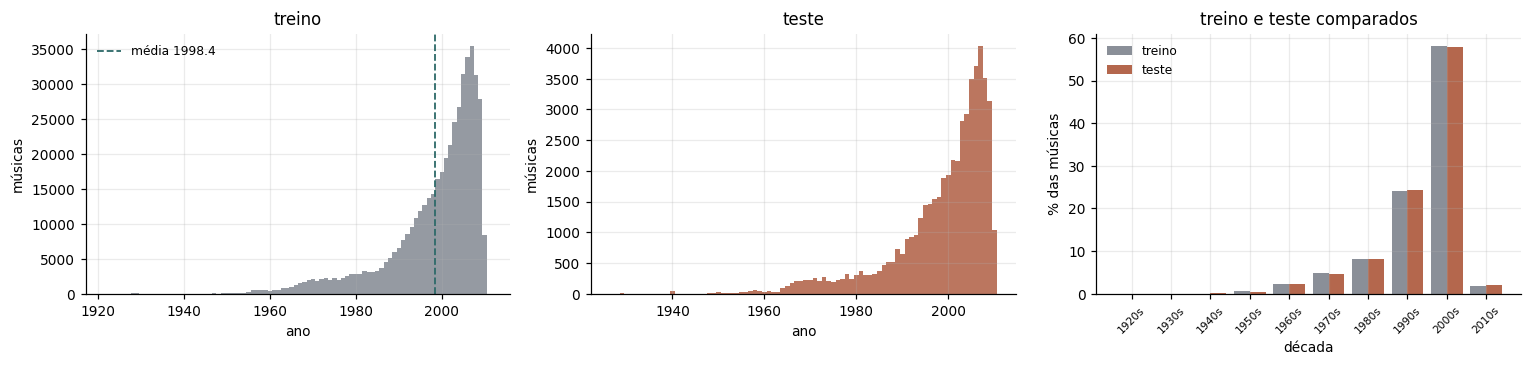

ALVO

  treino: 1922 a 2011, média 1998.39, mediana 2002, desvio 10.94
  teste : 1927 a 2010, média 1998.50, mediana 2002, desvio 10.85

  concentração no treino:
    de 1990 a 2011: 84.0%
    de 2000 a 2011: 59.8%
    de 2005 a 2011: 36.3%

REFERÊNCIAS (erro em anos)

  chutar a média do treino   : MAE 8.1131   RMSE 10.8525
  chutar a mediana do treino : MAE 7.5878

  variância do alvo no treino: 119.68   desvio 10.94


In [70]:
mae_media   = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))
mae_mediana = mean_absolute_error(y_test, np.full(len(y_test), np.median(y_train)))
rmse_media  = float(np.sqrt(mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
ax[0].hist(y_train, bins=np.arange(y_train.min(), y_train.max() + 2) - .5,
           color=COR_REF, alpha=.9)
ax[0].axvline(y_train.mean(), color=COR_KAL, ls="--", lw=1.2,
              label=f"média {y_train.mean():.1f}")
ax[0].set(xlabel="ano", ylabel="músicas", title="treino")
ax[0].legend(frameon=False, fontsize=8)

ax[1].hist(y_test, bins=np.arange(y_test.min(), y_test.max() + 2) - .5,
           color=COR_REW, alpha=.9)
ax[1].set(xlabel="ano", ylabel="músicas", title="teste")

dec_tr = (y_train // 10 * 10).astype(int)
dec_te = (y_test // 10 * 10).astype(int)
d = sorted(set(dec_tr) | set(dec_te))
ptr = [100 * (dec_tr == x).mean() for x in d]
pte = [100 * (dec_te == x).mean() for x in d]
x = np.arange(len(d))
ax[2].bar(x - .2, ptr, width=.4, color=COR_REF, label="treino")
ax[2].bar(x + .2, pte, width=.4, color=COR_REW, label="teste")
ax[2].set(xticks=x, xticklabels=[f"{v}s" for v in d], xlabel="década",
          ylabel="% das músicas", title="treino e teste comparados")
ax[2].tick_params(axis="x", labelrotation=45, labelsize=7)
ax[2].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

print("ALVO\n")
print(f"  treino: {y_train.min():.0f} a {y_train.max():.0f}, média {y_train.mean():.2f}, "
      f"mediana {np.median(y_train):.0f}, desvio {y_train.std():.2f}")
print(f"  teste : {y_test.min():.0f} a {y_test.max():.0f}, média {y_test.mean():.2f}, "
      f"mediana {np.median(y_test):.0f}, desvio {y_test.std():.2f}")
q = [50, 80, 90, 95, 99]
print(f"\n  concentração no treino:")
for lo, hi in [(1990, 2011), (2000, 2011), (2005, 2011)]:
    print(f"    de {lo} a {hi}: {100*((y_train>=lo)&(y_train<=hi)).mean():.1f}%")

print("\nREFERÊNCIAS (erro em anos)\n")
print(f"  chutar a média do treino   : MAE {mae_media:.4f}   RMSE {rmse_media:.4f}")
print(f"  chutar a mediana do treino : MAE {mae_mediana:.4f}")
print(f"\n  variância do alvo no treino: {y_train.var():.2f}   desvio {y_train.std():.2f}")

---
## 3.4 Como são os números

O que tem numa linha do arquivo, com valores de verdade em vez de estatística
agregada. Uma linha é uma música.

**O alvo, o `y`.** É a primeira coluna do arquivo, e é o ano de lançamento, um
inteiro entre 1922 e 2011. Ele não passa pelo thermometer, não vira bit e não
entra na retina. É o número que o modelo tem que devolver, e o MAE mede a
distância entre o ano previsto e o ano verdadeiro, em anos.

**Os atributos.** São as outras 90 colunas, todas contínuas. Elas são o que
passa pelo thermometer, vira retina binária e é fatiada em endereços de RAM
node. Dividem-se em dois grupos de grandeza bem diferente. As 12 primeiras são
a média de cada dimensão de timbre ao longo da música, e ficam na casa das
dezenas. As 78 seguintes são a covariância entre essas 12 dimensões, e chegam
às dezenas de milhares. Como o thermometer é ajustado atributo a atributo, cada
coluna é binarizada dentro da faixa dela, e essa diferença de escala entre os
dois grupos não atrapalha.

As cinco primeiras linhas do arquivo são todas de 2001, porque ele vem ordenado.
Por isso a célula mostra também cinco músicas espalhadas ao longo do treino, com
anos diferentes.


In [71]:
N_HEAD = 5
MEDIAS_TIMBRE = slice(0, 12)      # atributos 1 a 12
COVAR_TIMBRE  = slice(12, 90)     # atributos 13 a 90

print(f"CADA LINHA É UMA MÚSICA: 1 alvo + {N_ATRIB} atributos, "
      f"{len(X_train):,} músicas no treino\n")

print(f"O ALVO (y), as {N_HEAD} primeiras linhas\n")
print("   " + "".join(f"{v:>8.0f}" for v in y_train[:N_HEAD]))
print(f"\n   ano de lançamento, inteiro. Não é binarizado e não entra na retina.")
print(f"   no treino: {y_train.min():.0f} a {y_train.max():.0f}, "
      f"mediana {np.median(y_train):.0f}, desvio {y_train.std():.2f}, "
      f"{len(np.unique(y_train))} anos distintos")

print(f"\n\nOS {N_ATRIB} ATRIBUTOS, as {N_HEAD} primeiras linhas\n")
print("   1 a 12: MÉDIA de cada dimensão de timbre ao longo da música")
print(f"   {'linha':<7}" + "".join(f"{f'a{j+1}':>9}" for j in range(12)))
for i in range(N_HEAD):
    print(f"   {i:<7}" + "".join(f"{X_train[i, j]:>9.2f}" for j in range(12)))

print("\n   13 a 90: COVARIÂNCIA entre essas 12 dimensões (12 x 13 / 2 = 78)")
print(f"   {'linha':<7}" + "".join(f"{f'a{j+1}':>11}" for j in range(12, 18))
      + f"{'...':>7}" + "".join(f"{f'a{j+1}':>11}" for j in (88, 89)))
for i in range(N_HEAD):
    print(f"   {i:<7}" + "".join(f"{X_train[i, j]:>11.1f}" for j in range(12, 18))
          + f"{'...':>7}" + "".join(f"{X_train[i, j]:>11.1f}" for j in (88, 89)))
print("\n   o UCI não documenta qual par (i, j) é cada uma das 78 colunas")

print(f"\n\nAS MESMAS COLUNAS, EM {N_HEAD} MÚSICAS DE ANOS DIFERENTES\n")
_esp = np.linspace(0, len(X_train) - 1, N_HEAD).astype(int)
print(f"   {'linha':<9}{'ano':>6}" + "".join(f"{f'a{j+1}':>9}" for j in range(6))
      + f"{'...':>7}" + "".join(f"{f'a{j+1}':>10}" for j in (13, 89)))
for i in _esp:
    print(f"   {i:<9,}{y_train[i]:>6.0f}"
          + "".join(f"{X_train[i, j]:>9.2f}" for j in range(6))
          + f"{'...':>7}" + "".join(f"{X_train[i, j]:>10.1f}" for j in (13, 89)))

print(f"\n\nAS GRANDEZAS, sobre as {len(X_train):,} músicas do treino\n")
print(f"   {'grupo':<26}{'quantos':>9}{'menor':>12}{'mediana':>12}"
      f"{'maior':>12}{'|x| médio':>12}")
for rot, sl in [("médias de timbre  (1-12)", MEDIAS_TIMBRE),
                ("covariâncias     (13-90)", COVAR_TIMBRE)]:
    b = X_train[:, sl]
    print(f"   {rot:<26}{b.shape[1]:>9}{b.min():>12.1f}{np.median(b):>12.1f}"
          f"{b.max():>12.1f}{np.abs(b).mean():>12.1f}")

print(f"\n\nATRIBUTO A ATRIBUTO, os 12 primeiros\n")
print(f"   {'atributo':>9}{'menor':>11}{'mediana':>11}{'maior':>11}{'desvio':>11}")
for j in range(12):
    c_ = X_train[:, j]
    print(f"   {'a'+str(j+1):>9}{c_.min():>11.1f}{np.median(c_):>11.1f}"
          f"{c_.max():>11.1f}{c_.std():>11.1f}")

print(f"\n   e os 78 seguintes, resumidos pelo desvio de cada um\n")
_dp = X_train[:, COVAR_TIMBRE].std(axis=0)
print(f"   menor desvio  {_dp.min():>10.1f}   (atributo a{13 + int(_dp.argmin())})")
print(f"   mediana       {np.median(_dp):>10.1f}")
print(f"   maior desvio  {_dp.max():>10.1f}   (atributo a{13 + int(_dp.argmax())})")
print(f"   razão entre o maior e o menor: {_dp.max()/_dp.min():,.0f}x")


CADA LINHA É UMA MÚSICA: 1 alvo + 90 atributos, 463,715 músicas no treino

O ALVO (y), as 5 primeiras linhas

       2001    2001    2001    2001    2001

   ano de lançamento, inteiro. Não é binarizado e não entra na retina.
   no treino: 1922 a 2011, mediana 2002, desvio 10.94, 89 anos distintos


OS 90 ATRIBUTOS, as 5 primeiras linhas

   1 a 12: MÉDIA de cada dimensão de timbre ao longo da música
   linha         a1       a2       a3       a4       a5       a6       a7       a8       a9      a10      a11      a12
   0          49.94    21.47    73.08     8.75   -17.41   -13.10   -25.01   -12.23     7.83    -2.47     3.32    -2.32
   1          48.73    18.43    70.33    12.95   -10.32   -24.84     8.77    -0.92    18.77     4.59     2.22     0.34
   2          50.96    31.86    55.82    13.42    -6.58   -18.55    -3.28    -2.35    16.07     1.40     2.74     0.83
   3          48.25    -1.90    36.30     2.59     0.97   -26.22     5.05   -10.34     3.55    -6.36     6.63    -3.35
 

## 3.5 Quanto da retina carrega informação

No House Prices, 88,7% dos bits eram cópia de outros bits da mesma coluna,
porque 294 das 332 colunas eram indicadores binários vindos do one-hot. Aqui os
90 atributos são contínuos, então a expectativa é outra, mas isso é medição e
não suposição.

Conta padrões distintos que cada atributo gera no bloco de bits dele.

In [72]:
for res in (20, 25):
    enc = build_encoders(X_train, res)
    amostra = X_train[np.random.default_rng(0).choice(
        len(X_train), min(20000, len(X_train)), replace=False)]
    Xb = apply_encoders(amostra, enc)
    dist = np.array([len(np.unique(Xb[:, j*res:(j+1)*res], axis=0)) for j in range(N_ATRIB)])
    print(f"resolução {res}: retina de {N_ATRIB*res} bits")
    print(f"  padrões distintos por atributo: mínimo {dist.min()}, "
          f"mediana {int(np.median(dist))}, máximo {dist.max()}")
    print(f"  soma dos padrões distintos: {dist.sum():,} de {N_ATRIB*res:,} bits")
    print(f"  atributos que geram 2 padrões ou menos: {(dist <= 2).sum()}")
    print(f"  densidade da retina: {Xb.mean():.3f} dos bits em 1\n")

resolução 20: retina de 1800 bits
  padrões distintos por atributo: mínimo 6, mediana 11, máximo 18
  soma dos padrões distintos: 980 de 1,800 bits
  atributos que geram 2 padrões ou menos: 0
  densidade da retina: 0.410 dos bits em 1

resolução 25: retina de 2250 bits
  padrões distintos por atributo: mínimo 7, mediana 13, máximo 22
  soma dos padrões distintos: 1,184 de 2,250 bits
  atributos que geram 2 padrões ou menos: 0
  densidade da retina: 0.415 dos bits em 1



---
## 3.6 O que já foi publicado sobre esta divisão

O artigo que apresentou o dataset usa a predição de ano como estudo de caso e
publica resultados sobre exatamente a divisão da seção 3.2.

> Thierry Bertin-Mahieux, Daniel P. W. Ellis, Brian Whitman, Paul Lamere.
> **The Million Song Dataset.** *12th International Society for Music
> Information Retrieval Conference (ISMIR 2011)*, p. 591-596.
> https://ismir2011.ismir.net/papers/OS6-1.pdf

Tabela 5 do artigo, sobre as 51.630 músicas de teste. A primeira coluna é a
diferença absoluta média, que é o MAE, e a segunda é a raiz da diferença
quadrática média, que é o RMSE.

| método | MAE | RMSE |
|---|---|---|
| predição constante (média do treino, 1998,4) | 8,13 | 10,80 |
| 1-NN | 9,81 | 13,99 |
| 50-NN | 7,58 | 10,20 |
| Vowpal Wabbit | **6,14** | **8,76** |

Duas leituras que valem registrar. O 1-NN é **pior** que chutar a constante, o
que diz que a vizinhança imediata no espaço de timbre não carrega o ano. E o
50-NN, com 7,58, empata com chutar a mediana do treino, que dá 7,59 na conta da
seção 3.3. Só o Vowpal Wabbit, um modelo linear treinado por gradiente
estocástico, se afasta do trivial de forma clara.

O alvo a bater, portanto, é 6,14 de MAE, e o piso do trivial é 8,11.


In [73]:
# Tabela 5 de Bertin-Mahieux et al., ISMIR 2011. Medida sobre esta mesma
# divisão, então é comparável linha a linha com o que sai deste notebook.
REF_MSD = [("predição constante (artigo)", 8.13, 10.80),
           ("1-NN (artigo)",               9.81, 13.99),
           ("50-NN (artigo)",              7.58, 10.20),
           ("Vowpal Wabbit (artigo)",      6.14,  8.76)]

print("PUBLICADO, sobre as 51.630 músicas de teste\n")
print(f"  {'método':<30}{'MAE':>7}{'RMSE':>8}")
for n_, mae_, rmse_ in REF_MSD:
    print(f"  {n_:<30}{mae_:>7.2f}{rmse_:>8.2f}")

print(f"\nCONFERÊNCIA da nossa leitura do arquivo\n")
print(f"  predição constante recalculada aqui: "
      f"{mean_absolute_error(y_test, np.full(len(y_test), y_train.mean())):.3f}")
print(f"  o artigo reporta                   : 8.13")
print("\n  (no modo reduzido os dois não batem, porque o teste é uma subamostra)")


PUBLICADO, sobre as 51.630 músicas de teste

  método                            MAE    RMSE
  predição constante (artigo)      8.13   10.80
  1-NN (artigo)                    9.81   13.99
  50-NN (artigo)                   7.58   10.20
  Vowpal Wabbit (artigo)           6.14    8.76

CONFERÊNCIA da nossa leitura do arquivo

  predição constante recalculada aqui: 8.113
  o artigo reporta                   : 8.13

  (no modo reduzido os dois não batem, porque o teste é uma subamostra)


---
# Seção 4 — R-KalWeNN

A Regression WiSARD guarda contador e soma. O R-KalWeNN troca os dois campos da
célula por estados de uma recursão de Kalman escalar:

| campo | o que é | converge para |
|---|---|---|
| $c_k$ | confiança do endereço, entre 0 e 1 | 1, de forma assintótica |
| $y_k$ | valor esperado de $y$ naquele endereço | a média local de $y$ |
| $p_{c,k}$, $p_{y,k}$ | covariância de cada um | regime dado por $q$ e $r$ |

Recursão, a cada observação:

$$
\bar{p} = p + q \qquad K = \frac{\bar{p}}{\bar{p} + r} \qquad
x \leftarrow x + K\,(z - x) \qquad p \leftarrow (1-K)\,\bar{p}
$$

Predição, com a média escolhida sobre os pares $(c_k, y_k)$ das células que o
exemplo endereça e que têm evidência:

$$
\hat{y} \;=\; \text{média}_{\,k}\big(c_k,\, y_k\big)
$$

## 4.1 A atualização de `c` e de `y`

**Estados iniciais.** $x_{0,c} = x_{0,y} = 0$, fixos. As covariâncias iniciais
são hiperparâmetros e nunca são zero: covariância nula não descreve uma
gaussiana, descreve um ponto exato no espaço de estados.

**A atualização de $c$.** Observação $z = 1$ quando o endereço é acessado;
célula não acessada não é tocada. É o `KalmanWiSARD` de classificação sem
alteração.

**A atualização de $y$.** $p_y$ cresce $q_y$ uma vez por acesso, e a correção
roda só no acesso, porque só aí existe um alvo para observar:

$$
p_y \leftarrow p_y + q_y, \qquad
K_y = \frac{p_y}{p_y + r_y}, \qquad
y \leftarrow y + K_y (y_i - y)
$$

Célula não acessada não é tocada por nenhuma das duas atualizações.

---
## 4.2 O que a confiança mede, e o que ela não mede

$c$ vai assintoticamente para 1, mas nenhuma célula chega lá: o que importa é o
valor depois das visitas que ela de fato recebe. Como o passo da atualização não
depende do valor observado, $c$ é função determinística do **número de visitas**.

**O que ela é.** Um contador que satura, com retorno decrescente por visita, e a
taxa de saturação é o hiperparâmetro.

**O que ela não é.** Uma medida de acerto. Duas células com o mesmo número de
visitas têm exatamente o mesmo $c$, mesmo que os $y$ de uma concordem e os da
outra não. Isso vale para $p$ também, porque a recursão da covariância não
contém $z$.

**Implementação.** Como $c$ só depende do contador, nada precisa tocar as
células não acessadas. A memória fica esparsa, com apenas as células visitadas,
e não há teto no `address_size`, o que é o que permite a varredura da seção 8.

In [74]:
class IndiceRK:
    """(ram, address) -> slot compacto, construído uma vez por (retina, treino).

    Só existem células que algum exemplo de treino visitou, o que vale para
    qualquer `address_size`: uma tabela densa de 2^address entradas por RAM node
    seria impossível já com 20 bits.
    """

    def __init__(self, retina, addr_fit):
        self.retina = retina
        # int32 explícito: `empty_like(addr_fit)` herdaria o tipo do endereço,
        # que agora é uint8, e os slots vão muito além de 255.
        self.slots_fit = np.empty(addr_fit.shape, dtype=np.int32)
        self._tab, off = [], 0
        for r_ in range(retina.n_rams):
            uniq, inv = np.unique(addr_fit[:, r_], return_inverse=True)
            self.slots_fit[:, r_] = inv + off
            self._tab.append((uniq, off))
            off += len(uniq)
        self.n_celulas = off

    def slots(self, addr):
        """(n, n_rams), com -1 onde o endereço não apareceu no treino."""
        out = np.full(addr.shape, -1, dtype=np.int32)
        for r_ in range(self.retina.n_rams):
            uniq, off = self._tab[r_]
            pos = np.clip(np.searchsorted(uniq, addr[:, r_]), 0, len(uniq) - 1)
            ok = uniq[pos] == addr[:, r_]
            out[ok, r_] = off + pos[ok]
        return out


print("IndiceRK definido")

IndiceRK definido


In [75]:
class RKalWeNN:
    """R-KalWeNN: Kalman nos dois campos da célula. Memória esparsa.

    ATUALIZAÇÃO DE c   observação z = 1 no acesso; célula não acessada não é
                       tocada. Como a recursão da covariância não contém z, o
                       estado c é função determinística do NÚMERO de visitas,
                       então ele é montado no fim, a partir dos contadores, sem
                       precisar de laço por exemplo.

    ATUALIZAÇÃO DE y   p_y cresce q_y uma vez por acesso, e a correção
                       roda só no acesso. Célula não acessada não é tocada
                       por nenhuma das duas.

    As duas coisas juntas deixam a memória esparsa: só existem células que algum
    exemplo de treino visitou. Não há teto no `address_size`.
    """

    def __init__(self, address_size, mapping, media=None,
                 q_c=1e-5, r_c=1.0, p0_c=1e-1,
                 q_y=1.5e-3, r_y=1.0, p0_y=144.0,
                 x0_c=0.0, x0_y=0.0, seed=0, indice=None):
        self.retina = Retina(address_size, mapping)
        self.media = media if media is not None else KSimpleMean()
        self.q_c, self.r_c, self.p0_c = q_c, r_c, p0_c
        self.q_y, self.r_y, self.p0_y = q_y, r_y, p0_y
        self.x0_c, self.x0_y, self.seed = x0_c, x0_y, seed
        self.indice = indice

    @property
    def n_rams_(self):
        return self.retina.n_rams

    def tabela_c(self, nmax):
        """c(n) para n = 0..nmax. Não depende dos dados, só das covariâncias."""
        tab = np.zeros(nmax + 1)
        x, p = self.x0_c, self.p0_c
        for n in range(1, nmax + 1):
            pb = p + self.q_c
            k = pb / (pb + self.r_c)
            x += k * (1.0 - x)
            p = (1.0 - k) * pb
            tab[n] = x
        return tab

    def fit(self, Xb=None, y=None, addr=None):
        y = np.asarray(y, dtype=float)
        if self.indice is None:
            self.indice = IndiceRK(self.retina,
                                   self.retina.enderecos(Xb) if addr is None else addr)
        idx = self.indice
        ordem = np.random.default_rng(self.seed).permutation(len(y))

        Y    = np.full(idx.n_celulas, self.x0_y)
        PY   = np.full(idx.n_celulas, self.p0_y)
        cont = np.zeros(idx.n_celulas, dtype=np.int64)

        for i in ordem:
            s = idx.slots_fit[i]
            pp = PY[s] + self.q_y                      # predição, uma por visita
            ky = pp / (pp + self.r_y)                  # correção, só no acesso
            Y[s] += ky * (y[i] - Y[s])
            PY[s] = (1.0 - ky) * pp
            cont[s] += 1

        self.tab_c_ = self.tabela_c(int(cont.max()) if len(cont) else 0)
        self._C, self._Y, self._PY, self._cont = self.tab_c_[cont], Y, PY, cont
        self.n_celulas_ = idx.n_celulas
        return self

    def predict(self, Xb=None, media=None, slots=None):
        media = media or self.media
        if slots is None:
            slots = self.indice.slots(self.retina.enderecos(Xb))
        saida = np.empty(len(slots))
        for i in range(len(slots)):
            s = slots[i]
            ok = s >= 0
            pares = list(zip(self._C[s[ok]], self._Y[s[ok]]))
            saida[i] = media.calculate(pares) if pares else np.nan
        return saida

    def memoria_bytes(self):
        return self.n_celulas_ * 40    # chave + 4 floats


print("RKalWeNN definida (memória esparsa)")

RKalWeNN definida (memória esparsa)


## 5.0 A avaliação vetorizada

As médias em classe da seção 2.2 são a definição, e percorrem as 1494 RAM nodes
em laço Python. No grid isso é rodado $729 \times 3 \times 6$ vezes por variante
e domina o tempo.

Todas as seis se escrevem como reduções sobre matrizes $(n_{\text{teste}},
n_{\text{rams}})$, inclusive a mediana ponderada, que vira um `argsort` mais uma
soma acumulada. As duas formas foram conferidas uma contra a outra: diferença de
arredondamento, da ordem de $10^{-14}$, e mesmo padrão de NaN.

In [76]:
def coleta(modelo, slots):
    """(C, Y, V) de (n, n_rams) a partir dos slots do conjunto avaliado."""
    ok = slots >= 0
    s = np.where(ok, slots, 0)
    return modelo._C[s], modelo._Y[s], ok


def medias_vetorizadas(C, Y, V, nomes):
    """As seis médias ponderadas, em forma de redução sobre matrizes."""
    Cm = np.where(V, C, 0.0)
    sc = Cm.sum(1)
    ok = sc > 0
    V2 = V & (Y > 0)                       # harmônicas exigem y > 0
    Cm2 = np.where(V2, C, 0.0)
    sc2 = Cm2.sum(1)
    Yp = np.where(V2, Y, 1.0)              # só para dividir com segurança
    fin = lambda v, val: np.where(val, v, np.nan)
    out = {}

    if "K-SimpleMean" in nomes:
        out["K-SimpleMean"] = fin((Cm * Y).sum(1) / np.where(ok, sc, 1), ok)
    if "K-PowerMean(2)" in nomes:
        out["K-PowerMean(2)"] = fin(np.sqrt((Cm * Y ** 2).sum(1) / np.where(ok, sc, 1)), ok)
    if "K-HarmonicMean" in nomes:
        s = (Cm2 / Yp).sum(1); o2 = s > 0
        out["K-HarmonicMean"] = fin(sc2 / np.where(o2, s, 1), o2)
    if "K-HarmonicPower(2)" in nomes:
        s = (Cm2 / Yp ** 2).sum(1); o2 = s > 0
        out["K-HarmonicPower(2)"] = fin(np.sqrt(sc2 / np.where(o2, s, 1)), o2)
    if "K-ExponentialMean" in nomes:
        # mesma estabilização da KExponentialMean: subtrai o maior y da linha
        Ys = np.where(V, Y, -np.inf)
        mx = Ys.max(1, keepdims=True)
        mx = np.where(np.isfinite(mx), mx, 0.0)          # linhas sem célula válida
        out["K-ExponentialMean"] = fin(
            mx[:, 0] + np.log((Cm * np.exp(Ys - mx)).sum(1) / np.where(ok, sc, 1)), ok)
    if "K-Median" in nomes:
        o = np.argsort(Y, axis=1, kind="stable")
        Cs = np.take_along_axis(Cm, o, 1); Ys = np.take_along_axis(Y, o, 1)
        idx = (np.cumsum(Cs, axis=1) >= (sc / 2.0)[:, None]).argmax(1)
        out["K-Median"] = fin(Ys[np.arange(len(Y)), idx], ok)
    return out


print("medias_vetorizadas definida")

medias_vetorizadas definida


In [77]:
def avalia(modelo, slots, y_ref, nomes):
    """Uma memória treinada, todas as médias. {nome: (MAE, RMSE, R2, nao_finito)}."""
    C, Y, V = coleta(modelo, slots)
    preds = medias_vetorizadas(C, Y, V, nomes)
    ss_tot = float(np.sum((y_ref - y_ref.mean()) ** 2))
    out = {}
    for nome, pr in preds.items():
        nao_fin = int((~np.isfinite(pr)).sum())
        if nao_fin:
            bons = pr[np.isfinite(pr)]
            pr = np.where(np.isfinite(pr), pr, bons.mean() if len(bons) else 0.0)
        out[nome] = (mean_absolute_error(y_ref, pr),
                     float(np.sqrt(mean_squared_error(y_ref, pr))),
                     1.0 - float(np.sum((y_ref - pr) ** 2)) / ss_tot,
                     nao_fin)
    return out


print("avalia definida")

avalia definida


---
# Seção 6 — Grid search

Aqui o thermometer e o address size **entram no grid**, junto das seis
covariâncias e do tipo de média. Não há configuração de codificação fixada.

Todos os hiperparâmetros estão na célula da busca, e não numa célula de
configuração distante, para o que se lê ser o que roda.

Para cada par (thermometer, address) a binarização e o índice são construídos
uma vez e reaproveitados por todas as covariâncias. As seis médias saem do mesmo
ajuste, porque a média só age na predição.

**Custo de tempo.** Um ajuste custa aproximadamente `n_treino × n_rams ×
134 ns`. Com o treino completo de 463.715 exemplos e 405 RAM nodes isso dá 25 s
por ajuste, e o grid inteiro passa de dez horas. Quem controla o tamanho é o
`MODO` da seção 3.2, e a célula abaixo imprime a estimativa antes de rodar.

**Custo de memória.** `Retina.enderecos` monta `Xb[:, mapping] * pesos`, que é
um `int64` de forma `(n, n_rams, address_size)`, ou seja `n × retina_bits × 8`
bytes, mais a cópia `uint8` do fancy-index. Com o treino completo e uma retina
de 2.250 bits o pico medido é de 10,4 GB, então `MODO = "completo"` **não roda** nesta
máquina sem antes fatiar essa conta em blocos. A tabela abaixo traz a coluna
`pico RAM` e marca os casos que estouram.

In [78]:
# ═══════════════ HIPERPARÂMETROS DESTA BUSCA ════════════════════════════════
GRID_THERM = [20]
GRID_ADDR  = [6]

GRID_Q_C  = [0.001]   #1e-6, 1e-4, 1e-3     # atualização de c
GRID_R_C  = [1]
GRID_P0_C = [1.0] #0.01, 0.05, 0.2, 1.0

GRID_Q_Y  = [120.0] #12.0, 120.0   # atualização de y
GRID_R_Y  = [120]
GRID_P0_Y = [1200.0] #0.3, 1.2, 12.0, 120.0, 1200.0

# Estados iniciais. x0_c fica em 0 porque c é confiança em [0,1] e começar sem
# confiança nenhuma é o que a observação z = 1 corrige. x0_y vai para a mediana
# do treino: com x0_y = 0 e o alvo por volta de 2000 a célula precisaria
# percorrer 2000 anos, e a maioria só recebe uma ou duas visitas.
X0_C = 0.0
X0_Y = float(np.median(y_train))
SEEDS_GRID = (0,)

MEDIAS_NO_GRID = ["K-SimpleMean", "K-PowerMean(2)", "K-HarmonicMean",
                  "K-HarmonicPower(2)", "K-ExponentialMean", "K-Median"]

ARQ_GRID = "grid_year_prediction.csv"
# ════════════════════════════════════════════════════════════════════════════

combos = list(product(GRID_Q_C, GRID_R_C, GRID_P0_C, GRID_Q_Y, GRID_R_Y, GRID_P0_Y))
PARES = [(t, a) for t in GRID_THERM for a in GRID_ADDR]

print("EIXOS DA BUSCA\n")
for nome, val in [("thermometer", GRID_THERM), ("address", GRID_ADDR),
                  ("q_c", GRID_Q_C), ("r_c", GRID_R_C), ("p0_c", GRID_P0_C),
                  ("q_y", GRID_Q_Y), ("r_y", GRID_R_Y), ("p0_y", GRID_P0_Y),
                  ("médias", MEDIAS_NO_GRID), ("seeds", list(SEEDS_GRID))]:
    s_ = str(val)
    print(f"  {nome:<12}{len(val):>3} níveis   {s_ if len(s_) < 60 else s_[:57]+'...'}")
print(f"  {'x0_c':<12}            {X0_C}")
print(f"  {'x0_y':<12}            {X0_Y:g}   (mediana do treino)")

seg_por_exemplo_ram = 134e-9          # medido no notebook 06

# Pico de memória de Retina.enderecos: ele cria Xb[:, mapping] * pesos, que é
# um int64 de (n, n_rams, address_size), ou seja n x retina_bits x 8 bytes,
# mais a cópia uint8 do fancy-index. Isso domina tudo o mais no notebook.
# O fator 10 vem de medição com tracemalloc, não da conta: a conta dá 9 e o
# alocador gasta cerca de 11% a mais.
def pico_gb(n, bits):
    return n * bits * 10 / 1e9

print(f"\n{'therm':>6}{'addr':>6}{'retina':>8}{'rams':>7}{'1 ajuste':>11}"
      f"{'todas as covariâncias':>24}{'pico RAM':>11}")
total = 0.0
for t, a in PARES:
    r = (t * N_ATRIB) // a
    seg = N_TREINO * r * seg_por_exemplo_ram
    total += seg * len(combos) * len(SEEDS_GRID)
    pico = pico_gb(max(N_TREINO, len(X_test)), t * N_ATRIB)
    print(f"{t:>6}{a:>6}{t*N_ATRIB:>8}{r:>7}{seg:>10.1f}s"
          f"{seg*len(combos)*len(SEEDS_GRID)/60:>21.0f} min"
          f"{pico:>9.2f} GB{'  <-- estoura' if pico > 4 else ''}")
print(f"\n{len(PARES)} pares x {len(combos)} covariâncias x {len(SEEDS_GRID)} seeds "
      f"= {len(PARES)*len(combos)*len(SEEDS_GRID):,} ajustes")
print(f"estimativa total: {total/60:,.0f} min ({total/3600:,.1f} h)")
print(f"  começando agora, terminaria por volta de "
      f"{time.strftime('%d/%m %H:%M', time.localtime(time.time() + total))}")

EIXOS DA BUSCA

  thermometer   1 níveis   [20]
  address       1 níveis   [6]
  q_c           1 níveis   [0.001]
  r_c           1 níveis   [1]
  p0_c          1 níveis   [1.0]
  q_y           1 níveis   [120.0]
  r_y           1 níveis   [120]
  p0_y          1 níveis   [1200.0]
  médias        6 níveis   ['K-SimpleMean', 'K-PowerMean(2)', 'K-HarmonicMean', 'K-H...
  seeds         1 níveis   [0]
  x0_c                    0.0
  x0_y                    2002   (mediana do treino)

 therm  addr  retina   rams   1 ajuste   todas as covariâncias   pico RAM
    20     6    1800    300      18.6s                    0 min     8.35 GB  <-- estoura

1 pares x 1 covariâncias x 1 seeds = 1 ajustes
estimativa total: 0 min (0.0 h)
  começando agora, terminaria por volta de 30/08 19:36


## 6.1 A busca

Grava CSV parcial a cada par (thermometer, address).

In [79]:
with open(ARQ_GRID, "w") as f:
    f.write("therm,address,n_rams,media,q_c,r_c,p0_c,q_y,r_y,p0_y,"
            "MAE,MAE_dp,RMSE,R2,nao_finito\n")

linhas, t0, feitos = [], time.perf_counter(), 0
alvo_total = len(PARES) * len(combos)

for t, a in PARES:
    enc = build_encoders(X_train, t)
    Xb_tr, Xb_te = apply_encoders(X_train, enc), apply_encoders(X_test, enc)
    ret = Retina(a, sorteia_mapping(Xb_tr.shape[1], a, seed=SEED_MAPPING))
    idx = IndiceRK(ret, ret.enderecos(Xb_tr))
    sl_te = idx.slots(ret.enderecos(Xb_te))
    print(f"\ntherm {t}, address {a}: retina {Xb_tr.shape[1]}, {ret.n_rams} RAM nodes, "
          f"{idx.n_celulas:,} células ocupadas")

    for qc, rc, p0c, qy, ry, p0y in combos:
        acum = {m: [] for m in MEDIAS_NO_GRID}
        for s in SEEDS_GRID:
            mod = RKalWeNN(a, ret.mapping.ravel(), q_c=qc, r_c=rc, p0_c=p0c,
                           q_y=qy, r_y=ry, p0_y=p0y, x0_c=X0_C, x0_y=X0_Y,
                           seed=s, indice=idx).fit(y=y_train)
            for nome, v in avalia(mod, sl_te, y_test, MEDIAS_NO_GRID).items():
                acum[nome].append(v)
        for nome, vs in acum.items():
            arr = np.array([v[:3] for v in vs], dtype=float)
            linhas.append(dict(therm=t, address=a, n_rams=ret.n_rams, media=nome,
                               q_c=qc, r_c=rc, p0_c=p0c, q_y=qy, r_y=ry, p0_y=p0y,
                               MAE=arr[:, 0].mean(), MAE_dp=arr[:, 0].std(),
                               RMSE=arr[:, 1].mean(), R2=arr[:, 2].mean(),
                               nao_finito=int(max(v[3] for v in vs))))
        feitos += 1
        if feitos % 25 == 0:
            el = time.perf_counter() - t0
            print(f"  {feitos:>4}/{alvo_total}  {el/60:.1f} min, "
                  f"faltam ~{el/feitos*(alvo_total-feitos)/60:.0f} min, "
                  f"término ~{time.strftime('%H:%M', time.localtime(time.time() + el/feitos*(alvo_total-feitos)))}")

    pd.DataFrame(linhas).to_csv(ARQ_GRID, index=False)

grid = pd.DataFrame(linhas).sort_values("MAE").reset_index(drop=True)
MELHOR = grid.loc[0].to_dict()
print(f"\nconcluído em {(time.perf_counter()-t0)/60:.1f} min, "
      f"{len(grid):,} linhas em {ARQ_GRID}\n")
print("VENCEDOR")
for c_ in ["therm", "address", "n_rams", "media", "q_c", "r_c", "p0_c",
           "q_y", "r_y", "p0_y"]:
    print(f"  {c_:<8} = {MELHOR[c_]}")
print(f"  MAE  = {MELHOR['MAE']:.4f} ± {MELHOR['MAE_dp']:.4f}   anos")
print(f"  RMSE = {MELHOR['RMSE']:.4f}   R2 = {MELHOR['R2']:.4f}")


therm 20, address 6: retina 1800, 300 RAM nodes, 4,057 células ocupadas

concluído em 1.2 min, 6 linhas em grid_year_prediction.csv

VENCEDOR
  therm    = 20
  address  = 6
  n_rams   = 300
  media    = K-HarmonicPower(2)
  q_c      = 0.001
  r_c      = 1
  p0_c     = 1.0
  q_y      = 120.0
  r_y      = 120
  p0_y     = 1200.0
  MAE  = 7.8478 ± 0.0000   anos
  RMSE = 12.2668   R2 = -0.2778


## 6.2 As melhores configurações e o diagnóstico de borda

Vencedor num extremo de eixo indica faixa curta, não ótimo encontrado.

AS 12 MELHORES

 therm  address              media   q_c  r_c  p0_c  q_y  r_y  p0_y   MAE  MAE_dp      R2
    20        6 K-HarmonicPower(2) 0.001    1     1  120  120  1200 7.848       0 -0.2778
    20        6     K-HarmonicMean 0.001    1     1  120  120  1200 7.848       0 -0.2778
    20        6       K-SimpleMean 0.001    1     1  120  120  1200 7.848       0 -0.2779
    20        6     K-PowerMean(2) 0.001    1     1  120  120  1200 7.848       0  -0.278
    20        6  K-ExponentialMean 0.001    1     1  120  120  1200  7.91       0 -0.3025
    20        6           K-Median 0.001    1     1  120  120  1200 7.923       0 -0.3071

faixa de MAE: 7.8478 a 7.9229
chutar a média do treino: 8.1131

O vencedor caiu na borda de algum eixo?

  therm    = 20         MENOR nível
  address  = 6          MENOR nível
  q_c      = 0.001      MENOR nível
  r_c      = 1          MENOR nível
  p0_c     = 1          MENOR nível
  q_y      = 120        MENOR nível
  r_y      = 120        MENOR ní

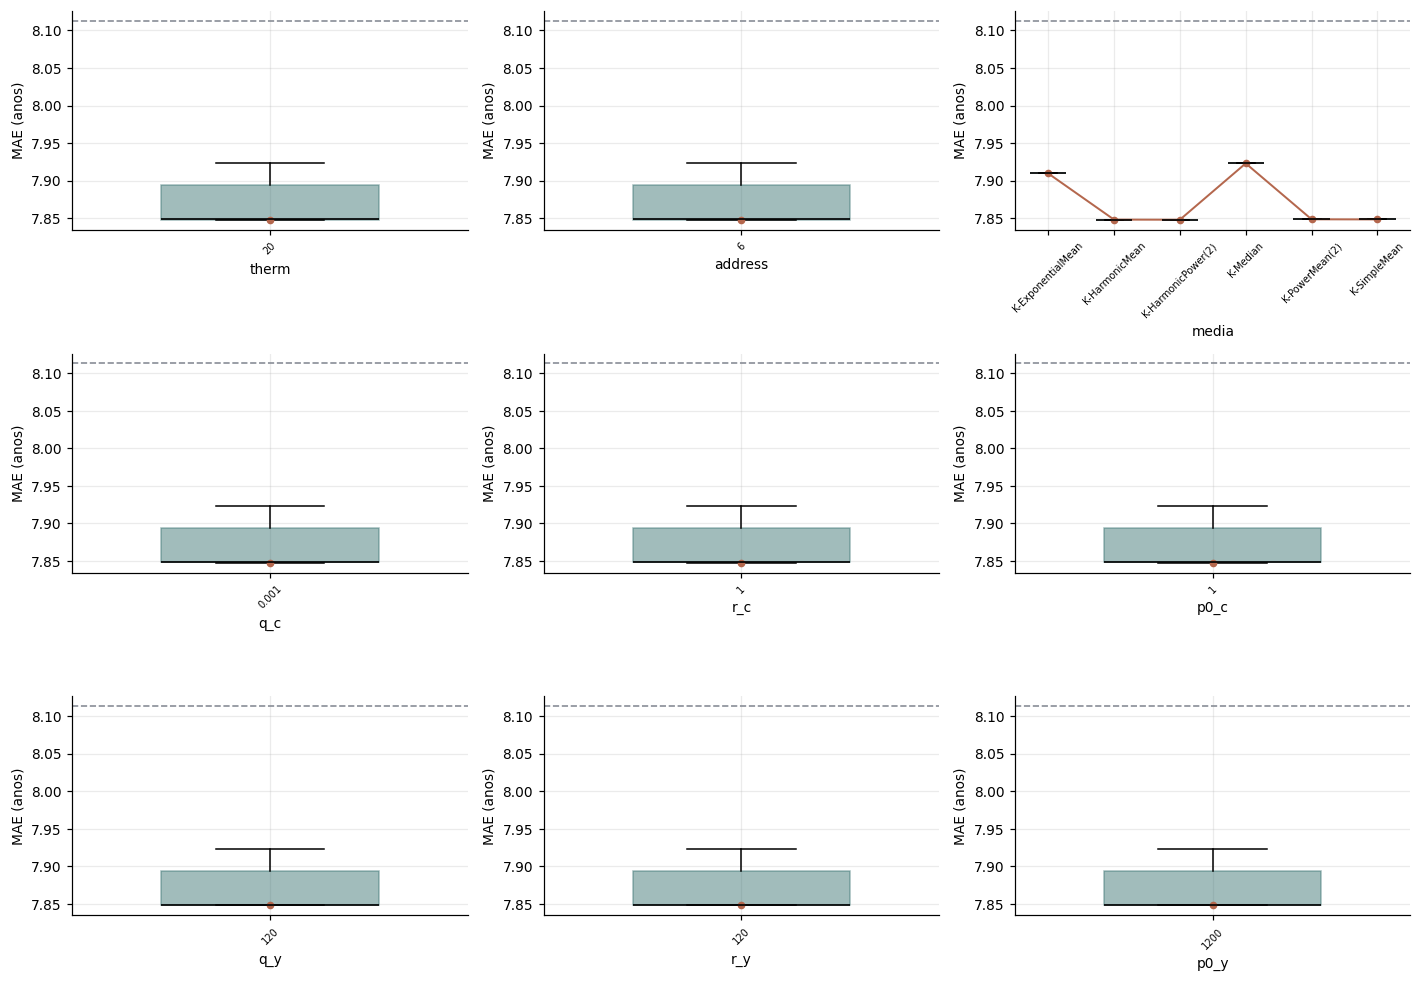

In [80]:
if "grid" not in globals():
    grid = pd.read_csv(ARQ_GRID).sort_values("MAE").reset_index(drop=True)
    MELHOR = grid.loc[0].to_dict()

cols = ["therm", "address", "media", "q_c", "r_c", "p0_c", "q_y", "r_y", "p0_y",
        "MAE", "MAE_dp", "R2"]
print("AS 12 MELHORES\n")
print(grid.head(12)[cols].to_string(index=False, float_format=lambda v: f"{v:.4g}"))
print(f"\nfaixa de MAE: {grid.MAE.min():.4f} a {grid.MAE.max():.4f}")
print(f"chutar a média do treino: {mae_media:.4f}")

print("\nO vencedor caiu na borda de algum eixo?\n")
for nome, niveis in [("therm", GRID_THERM), ("address", GRID_ADDR),
                     ("q_c", GRID_Q_C), ("r_c", GRID_R_C), ("p0_c", GRID_P0_C),
                     ("q_y", GRID_Q_Y), ("r_y", GRID_R_Y), ("p0_y", GRID_P0_Y)]:
    v = MELHOR[nome]
    onde = ("MENOR nível" if v == min(niveis)
            else "MAIOR nível" if v == max(niveis) else "interior")
    print(f"  {nome:<8} = {v:<10g} {onde}")
print(f"  média    = {MELHOR['media']}")

EIXOS = ["therm", "address", "media", "q_c", "r_c", "p0_c", "q_y", "r_y", "p0_y"]
fig, ax = plt.subplots(3, 3, figsize=(13, 9))
for a_, col in zip(ax.ravel(), EIXOS):
    niv = sorted(grid[col].unique(), key=lambda v: (isinstance(v, str), v))
    dados = [grid.loc[grid[col] == v, "MAE"].values for v in niv]
    bp = a_.boxplot(dados, positions=range(len(niv)), widths=.55, patch_artist=True,
                    medianprops=dict(color="black", lw=1.1),
                    flierprops=dict(marker=".", ms=2.5, alpha=.3))
    for caixa in bp["boxes"]:
        caixa.set(facecolor=COR_KAL, alpha=.45, edgecolor=COR_KAL)
    a_.plot(range(len(niv)), [d.min() for d in dados], "o-", color=COR_REW, ms=4, lw=1.3)
    a_.axhline(mae_media, color=COR_REF, ls="--", lw=1.1)
    a_.set(xticks=range(len(niv)),
           xticklabels=[f"{v:g}" if not isinstance(v, str) else v for v in niv],
           xlabel=col, ylabel="MAE (anos)")
    a_.tick_params(axis="x", labelrotation=45, labelsize=6.5)
plt.tight_layout(); plt.show()

---
# Seção 7 — A ReW na configuração vencedora

Roda a Regression WiSARD no thermometer e no address que deram o melhor MAE do
R-KalWeNN, com o mesmo `mapping`. Cada modelo com a família de média dele.

In [81]:
T_V, A_V = int(MELHOR["therm"]), int(MELHOR["address"])
print(f"configuração vencedora do R-KalWeNN: thermometer {T_V}, address {A_V}, "
      f"{int(MELHOR['n_rams'])} RAM nodes")
print(f"  {MELHOR['media']}, MAE {MELHOR['MAE']:.4f} anos\n")

enc_v = build_encoders(X_train, T_V)
Xb_tr_v, Xb_te_v = apply_encoders(X_train, enc_v), apply_encoders(X_test, enc_v)
map_v = sorteia_mapping(Xb_tr_v.shape[1], A_V, seed=SEED_MAPPING)

ss_tot = float(np.sum((y_test - y_test.mean()) ** 2))
linhas, t0 = [], time.perf_counter()
for nome, m in medias_rew().items():
    pr = RegressionWiSARD(A_V, m, map_v).fit(Xb_tr_v, y_train).predict(Xb_te_v)
    nf = int((~np.isfinite(pr)).sum())
    if nf:
        bons = pr[np.isfinite(pr)]
        pr = np.where(np.isfinite(pr), pr, bons.mean() if len(bons) else 0.0)
    linhas.append({"modelo": "ReW", "media": nome,
                   "MAE": mean_absolute_error(y_test, pr),
                   "RMSE": float(np.sqrt(mean_squared_error(y_test, pr))),
                   "R2": 1.0 - float(np.sum((y_test - pr) ** 2)) / ss_tot,
                   "nao_finito": nf})
    print(f"  ReW {nome:<18} ok  ({time.perf_counter()-t0:.0f} s)")

rew_venc = pd.DataFrame(linhas).sort_values("MAE").reset_index(drop=True)
print(f"\nReW em thermometer {T_V}, address {A_V}\n")
print(rew_venc.to_string(index=False, float_format=lambda v: f"{v:,.4f}"))

kal_ponto = grid[(grid.therm == T_V) & (grid.address == A_V)]
print("\n\nR-KalWeNN no mesmo ponto, melhor por média\n")
print(kal_ponto.groupby("media").MAE.min().sort_values()
      .to_string(float_format=lambda v: f"{v:.4f}"))

b_rew, b_kal = rew_venc.MAE.min(), kal_ponto.MAE.min()
print(f"\n\nMELHOR DE CADA UM, thermometer {T_V} address {A_V}\n")
print(f"  ReW ({rew_venc.loc[0,'media']}): {b_rew:.4f} anos")
print(f"  R-KalWeNN ({kal_ponto.loc[kal_ponto.MAE.idxmin(),'media']}): {b_kal:.4f} anos")
print(f"  diferença: {(b_kal/b_rew - 1)*100:+.1f}%")
print(f"  chutar a média do treino: {mae_media:.4f} anos")

configuração vencedora do R-KalWeNN: thermometer 20, address 6, 300 RAM nodes
  K-HarmonicPower(2), MAE 7.8478 anos

  ReW SimpleMean         ok  (172 s)
  ReW PowerMean(2)       ok  (349 s)
  ReW HarmonicMean       ok  (526 s)
  ReW HarmonicPower(2)   ok  (706 s)
  ReW ExponentialMean    ok  (883 s)
  ReW Median             ok  (1127 s)

ReW em thermometer 20, address 6

modelo            media    MAE    RMSE      R2  nao_finito
   ReW  ExponentialMean 7.9654 10.7768  0.0138           0
   ReW     PowerMean(2) 8.0903 10.8270  0.0046           0
   ReW     HarmonicMean 8.0904 10.8270  0.0046           0
   ReW HarmonicPower(2) 8.0904 10.8270  0.0046           0
   ReW       SimpleMean 8.1120 10.8455  0.0012           0
   ReW           Median 8.1143 10.8520 -0.0000           0


R-KalWeNN no mesmo ponto, melhor por média

media
K-HarmonicPower(2)   7.8478
K-HarmonicMean       7.8480
K-SimpleMean         7.8482
K-PowerMean(2)       7.8484
K-ExponentialMean    7.9096
K-Median            

---
# Seção 8 — Quantos endereços cada RAM node acessa, e quantas vezes

Na configuração vencedora do grid. Cada RAM node tem `2^address` endereços
possíveis, mas só existem os que algum exemplo de treino visitou.

Duas contagens diferentes, que não devem ser confundidas. **Endereços ocupados
por RAM node** é quantos endereços distintos aquele neurônio chegou a usar.
**Visitas por endereço** é quantos exemplos de treino caíram em cada um deles.
A soma das visitas de um RAM node é sempre o número de exemplos de treino,
porque todo exemplo endereça todos os RAM nodes.

In [82]:
# thermometer e address desta análise: por padrão os vencedores da varredura
if "grid" not in globals():
    grid = pd.read_csv(ARQ_GRID).sort_values("MAE").reset_index(drop=True)
T_A = int(grid.loc[0, "therm"])
A_A = int(grid.loc[0, "address"])
# ─────────────────────────────────────────────────────────────────────────────

Xb_a = apply_encoders(X_train, build_encoders(X_train, T_A))
ret_a = Retina(A_A, sorteia_mapping(Xb_a.shape[1], A_A, seed=SEED_MAPPING))
addr_a = ret_a.enderecos(Xb_a)

# visitas[r] = {endereço: quantas vezes}
ocupados, visitas = [], []
for r_ in range(ret_a.n_rams):
    _, cont_r = np.unique(addr_a[:, r_], return_counts=True)
    ocupados.append(len(cont_r))
    visitas.append(cont_r)
ocupados = np.array(ocupados)
todas = np.concatenate(visitas)
min_por_ram = np.array([v.min() for v in visitas])
max_por_ram = np.array([v.max() for v in visitas])
med_por_ram = np.array([np.median(v) for v in visitas])

print(f"thermometer {T_A}, address {A_A}  ->  {ret_a.n_rams} RAM nodes, "
      f"{ret_a.n_addr:,} endereços possíveis por RAM node")
print(f"{N_TREINO} exemplos de treino\n")

print("ENDEREÇOS OCUPADOS POR RAM NODE\n")
print(f"  mínimo {ocupados.min()}   mediana {int(np.median(ocupados))}   "
      f"máximo {ocupados.max()}   média {ocupados.mean():.1f}")
print(f"  de {ret_a.n_addr:,} possíveis, ou seja "
      f"{100*ocupados.mean()/ret_a.n_addr:.2f}% em média")
print(f"  total de células ocupadas: {ocupados.sum():,}")

print("\nVISITAS POR ENDEREÇO OCUPADO\n")
print(f"  mínimo {todas.min()}   mediana {int(np.median(todas))}   "
      f"máximo {todas.max()}   média {todas.mean():.1f}")
print(f"  endereços com 1 visita só: {100*(todas==1).mean():.1f}%")
print(f"  endereços com 2 ou mais  : {100*(todas>=2).mean():.1f}%")

print("\nO ENDEREÇO MENOS E MAIS VISITADO DE CADA RAM NODE\n")
print(f"  menos visitado : mínimo {min_por_ram.min()}, "
      f"mediana {int(np.median(min_por_ram))}, máximo {min_por_ram.max()}")
print(f"  mais visitado  : mínimo {max_por_ram.min()}, "
      f"mediana {int(np.median(max_por_ram))}, máximo {max_por_ram.max()}")
print(f"  mediana do RAM node : mínimo {med_por_ram.min():.1f}, "
      f"mediana {np.median(med_por_ram):.1f}, máximo {med_por_ram.max():.1f}")
print(f"\n  o RAM node mais concentrado tem um endereço com {max_por_ram.max()} "
      f"dos {N_TREINO} exemplos ({100*max_por_ram.max()/N_TREINO:.0f}%)")
print(f"  o RAM node mais espalhado tem no máximo {max_por_ram.min()} "
      f"exemplos num mesmo endereço")

print("\nOS 5 RAM NODES MAIS CONCENTRADOS E OS 5 MAIS ESPALHADOS\n")
tab = pd.DataFrame({"ram": np.arange(ret_a.n_rams), "enderecos_ocupados": ocupados,
                    "visitas_min": min_por_ram, "visitas_max": max_por_ram,
                    "visitas_mediana": med_por_ram})
print(tab.nlargest(5, "visitas_max").to_string(index=False))
print()
print(tab.nsmallest(5, "visitas_max").to_string(index=False))

thermometer 20, address 6  ->  300 RAM nodes, 64 endereços possíveis por RAM node
463715 exemplos de treino

ENDEREÇOS OCUPADOS POR RAM NODE

  mínimo 6   mediana 12   máximo 38   média 13.5
  de 64 possíveis, ou seja 21.13% em média
  total de células ocupadas: 4,057

VISITAS POR ENDEREÇO OCUPADO

  mínimo 1   mediana 8   máximo 463701   média 34290.0
  endereços com 1 visita só: 24.3%
  endereços com 2 ou mais  : 75.7%

O ENDEREÇO MENOS E MAIS VISITADO DE CADA RAM NODE

  menos visitado : mínimo 1, mediana 1, máximo 2
  mais visitado  : mínimo 163535, mediana 450417, máximo 463701
  mediana do RAM node : mínimo 1.0, mediana 7.0, máximo 473.0

  o RAM node mais concentrado tem um endereço com 463701 dos 463715 exemplos (100%)
  o RAM node mais espalhado tem no máximo 163535 exemplos num mesmo endereço

OS 5 RAM NODES MAIS CONCENTRADOS E OS 5 MAIS ESPALHADOS

 ram  enderecos_ocupados  visitas_min  visitas_max  visitas_mediana
 250                   8            1       463701          

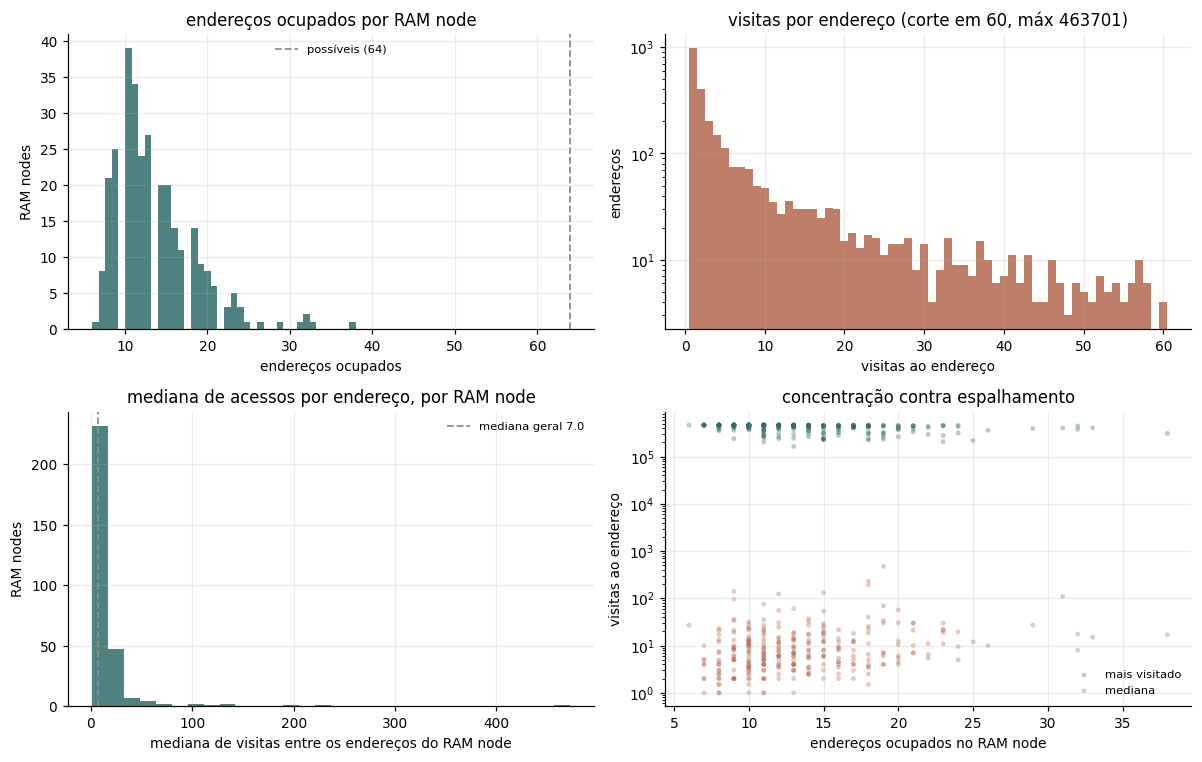

In [83]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7))

ax[0, 0].hist(ocupados, bins=40, color=COR_KAL, alpha=.85)
ax[0, 0].axvline(ret_a.n_addr, color=COR_REF, ls="--", lw=1.2,
                 label=f"possíveis ({ret_a.n_addr:,})")
ax[0, 0].set(xlabel="endereços ocupados", ylabel="RAM nodes",
             title="endereços ocupados por RAM node")
ax[0, 0].legend(frameon=False, fontsize=7.5)

ax[0, 1].hist(todas, bins=np.arange(1, min(todas.max(), 60) + 2) - .5,
              color=COR_REW, alpha=.85)
ax[0, 1].set(xlabel="visitas ao endereço", ylabel="endereços", yscale="log",
             title=f"visitas por endereço (corte em 60, máx {todas.max()})")

ax[1, 0].hist(med_por_ram, bins=30, color=COR_KAL, alpha=.85)
ax[1, 0].axvline(np.median(med_por_ram), color=COR_REF, ls="--", lw=1.2,
                 label=f"mediana geral {np.median(med_por_ram):.1f}")
ax[1, 0].set(xlabel="mediana de visitas entre os endereços do RAM node",
             ylabel="RAM nodes", title="mediana de acessos por endereço, por RAM node")
ax[1, 0].legend(frameon=False, fontsize=7.5)

ax[1, 1].scatter(ocupados, max_por_ram, s=10, alpha=.35, color=COR_KAL,
                 edgecolor="none", label="mais visitado")
ax[1, 1].scatter(ocupados, med_por_ram, s=10, alpha=.35, color=COR_REW,
                 edgecolor="none", label="mediana")
ax[1, 1].set(xlabel="endereços ocupados no RAM node", ylabel="visitas ao endereço",
             yscale="log", title="concentração contra espalhamento")
ax[1, 1].legend(frameon=False, fontsize=7.5)
plt.tight_layout(); plt.show()

---
# Seção 9 — Modelos de comparação

Quatro modelos fora da família WiSARD, ajustados nos mesmos `X_train` e
`y_train` e avaliados no mesmo `y_test`. Eles usam os 90 atributos contínuos
direto, sem thermometer e sem retina, que é como cada um deles é normalmente
aplicado.

| modelo | precisa de escala em X? | precisa de escala em y? |
|---|---|---|
| regressão linear | não | não |
| SVR (RBF) | **sim** | **sim** |
| decision tree | não | não |
| gradient boosting | não | não |

A regressão linear por mínimos quadrados é equivariante a transformação afim,
então padronizar não muda nada nela. As árvores decidem por comparação de
limiar, que é invariante a qualquer transformação monótona. O SVR é o único que
depende das duas escalas: o `C` e o `epsilon` são definidos nas unidades do
alvo, e com o ano valendo por volta de 2000 os valores padrão do sklearn tratam
o modelo inteiro como erro. Por isso, e só nele, o alvo entra padronizado via
`TransformedTargetRegressor`, que aplica `transform` no ajuste e
`inverse_transform` na predição. O MAE sai em anos nos quatro casos.

**Custo do SVR.** O SVR com kernel RBF resolve um problema quadrático cuja
matriz tem `n²` entradas, então o tempo cresce entre `n²` e `n³`. Com 463.715
exemplos de treino ele não roda: a matriz sozinha teria 2,1 × 10¹¹ entradas.
Por isso ele tem um teto próprio de exemplos, `SVR_MAX_TREINO`, e quando o
treino passa disso ele é ajustado numa subamostra, o que é dito na saída. Os
outros três rodam no treino inteiro.

**Sobre o gradient boosting.** É o `HistGradientBoostingRegressor` do sklearn,
mesma família do XGBoost, com histograma de bins. Entrou no lugar do XGBoost
porque este depende da `libomp`, cuja instalação no macOS 12 exige compilar o
`cmake` a partir do código.


In [84]:
# ═══════════════ MODELOS DE COMPARAÇÃO ══════════════════════════════════════
USAR = ["regressão linear", "SVR (RBF)", "decision tree", "gradient boosting"]

SVR_MAX_TREINO = 20_000        # acima disso o SVR é ajustado numa subamostra
SEED_BASELINE  = 0

PARAMS = {
    "SVR (RBF)":         dict(kernel="rbf", C=10.0, epsilon=0.1, gamma="scale",
                              cache_size=500),
    "decision tree":     dict(max_depth=12, min_samples_leaf=20,
                              random_state=SEED_BASELINE),
    "gradient boosting": dict(max_iter=400, max_depth=6, learning_rate=0.08,
                              l2_regularization=1.0, early_stopping=False,
                              random_state=SEED_BASELINE),
}
ARQ_BASE = "baselines_year_prediction.csv"
# ════════════════════════════════════════════════════════════════════════════

from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor


def constroi(nome):
    """Devolve (estimador, treino_maximo). treino_maximo None = treino inteiro."""
    if nome == "regressão linear":
        return LinearRegression(), None
    if nome == "SVR (RBF)":
        return TransformedTargetRegressor(
            regressor=make_pipeline(StandardScaler(), SVR(**PARAMS[nome])),
            transformer=StandardScaler()), SVR_MAX_TREINO
    if nome == "decision tree":
        return DecisionTreeRegressor(**PARAMS[nome]), None
    if nome == "gradient boosting":
        return HistGradientBoostingRegressor(**PARAMS[nome]), None
    raise ValueError(nome)


def bytes_modelo(est):
    """Bytes dos parâmetros que precisam ficar guardados para predizer."""
    if isinstance(est, TransformedTargetRegressor):
        return bytes_modelo(est.regressor_) + bytes_modelo(est.transformer_)
    if hasattr(est, "steps"):
        return sum(bytes_modelo(p) for _, p in est.steps)
    if isinstance(est, StandardScaler):
        return est.mean_.nbytes + est.scale_.nbytes
    if isinstance(est, LinearRegression):
        return est.coef_.nbytes + np.asarray(est.intercept_).nbytes
    if isinstance(est, SVR):
        return (est.support_vectors_.nbytes + est.dual_coef_.nbytes
                + est._intercept_.nbytes)
    if isinstance(est, DecisionTreeRegressor):
        t_ = est.tree_
        return (t_.children_left.nbytes + t_.children_right.nbytes + t_.feature.nbytes
                + t_.threshold.nbytes + t_.value.nbytes)
    if isinstance(est, HistGradientBoostingRegressor):
        return sum(pr.nodes.nbytes for etapa in est._predictors for pr in etapa)
    raise TypeError(type(est))


ss_tot_b = float(np.sum((y_test - y_test.mean()) ** 2))
rng_b = np.random.default_rng(SEED_BASELINE)
linhas_b = []

for nome in USAR:
    est, teto = constroi(nome)

    Xf, yf, obs = X_train, y_train, ""
    if teto is not None and teto < len(X_train):
        sel = np.sort(rng_b.choice(len(X_train), teto, replace=False))
        Xf, yf = X_train[sel], y_train[sel]
        obs = f"subamostra de {teto:,}"

    t0 = time.perf_counter()
    est.fit(Xf, yf)
    t_fit = time.perf_counter() - t0
    t0 = time.perf_counter()
    pred = np.asarray(est.predict(X_test), dtype=float)
    t_pred = time.perf_counter() - t0

    linhas_b.append({"modelo": nome, "n_treino": len(Xf),
                     "MAE": mean_absolute_error(y_test, pred),
                     "RMSE": float(np.sqrt(mean_squared_error(y_test, pred))),
                     "R2": 1.0 - float(np.sum((y_test - pred) ** 2)) / ss_tot_b,
                     "bytes": bytes_modelo(est),
                     "s_fit": t_fit, "s_pred": t_pred, "obs": obs})
    print(f"{nome:<20} MAE {linhas_b[-1]['MAE']:>7.4f}   "
          f"memória {linhas_b[-1]['bytes']/1024:>10,.1f} KB   "
          f"fit {t_fit:>7.1f}s   {obs}")

base_df = pd.DataFrame(linhas_b).sort_values("MAE").reset_index(drop=True)
base_df.to_csv(ARQ_BASE, index=False)
print(f"\n{len(base_df)} modelos, salvos em {ARQ_BASE}\n")
print(base_df[["modelo", "n_treino", "MAE", "RMSE", "R2", "bytes", "obs"]]
      .to_string(index=False, float_format=lambda v: f"{v:,.4f}"))


regressão linear     MAE  7.7333   memória        0.4 KB   fit     4.4s   
SVR (RBF)            MAE  6.7185   memória   12,317.7 KB   fit   303.4s   subamostra de 20,000
decision tree        MAE  6.9208   memória      237.0 KB   fit   119.6s   
gradient boosting    MAE  6.2830   memória    1,334.4 KB   fit    85.6s   

4 modelos, salvos em baselines_year_prediction.csv

           modelo  n_treino    MAE    RMSE     R2    bytes                  obs
gradient boosting    463715 6.2830  8.9949 0.3130  1366400                     
        SVR (RBF)     20000 6.7185  9.6042 0.2167 12613336 subamostra de 20,000
    decision tree    463715 6.9208  9.8413 0.1776   242680                     
 regressão linear    463715 7.7333 10.4282 0.0766      364                     


---
# Seção 10 — Resultado

MAE contra memória do modelo, para os dois modelos WiSARD e para os quatro
modelos de comparação da seção 9. A linha tracejada é o Vowpal Wabbit da
tabela 5 do artigo do MSD, que é o melhor resultado publicado sobre esta
divisão.

Memória é o tamanho dos parâmetros que precisam ficar guardados para predizer.
Para a ReW e o R-KalWeNN são as células ocupadas vezes 24 bytes, que é a chave
mais dois campos, com a ReW guardando contador e soma e o R-KalWeNN guardando
`c` e `y`, mais o mapping da retina e os limites do thermometer. Para os
modelos do sklearn é a soma dos arrays ajustados de cada um.


MEMÓRIA DOS MODELOS WISARD  (thermometer 20, address 6)

  células ocupadas                 4,057
  células x 24 bytes               97,368 bytes
  mapping da retina               14,400 bytes
  limites do thermometer           1,440 bytes
  total                          113,208 bytes

  a ReW e o R-KalWeNN ocupam o mesmo tanto: mesma retina, mesmo treino,
  logo o mesmo conjunto de células, e dois campos por célula nos dois


MAE E MEMÓRIA  (MODO = completo, teste com 51,630 exemplos)

                          modelo  MAE        KB
               gradient boosting 6.28  1,334.38
SVR (RBF) [subamostra de 20,000] 6.72 12,317.71
                   decision tree 6.92    236.99
                regressão linear 7.73      0.36
  R-KalWeNN (K-HarmonicPower(2)) 7.85    110.55
           ReW (ExponentialMean) 7.97    110.55


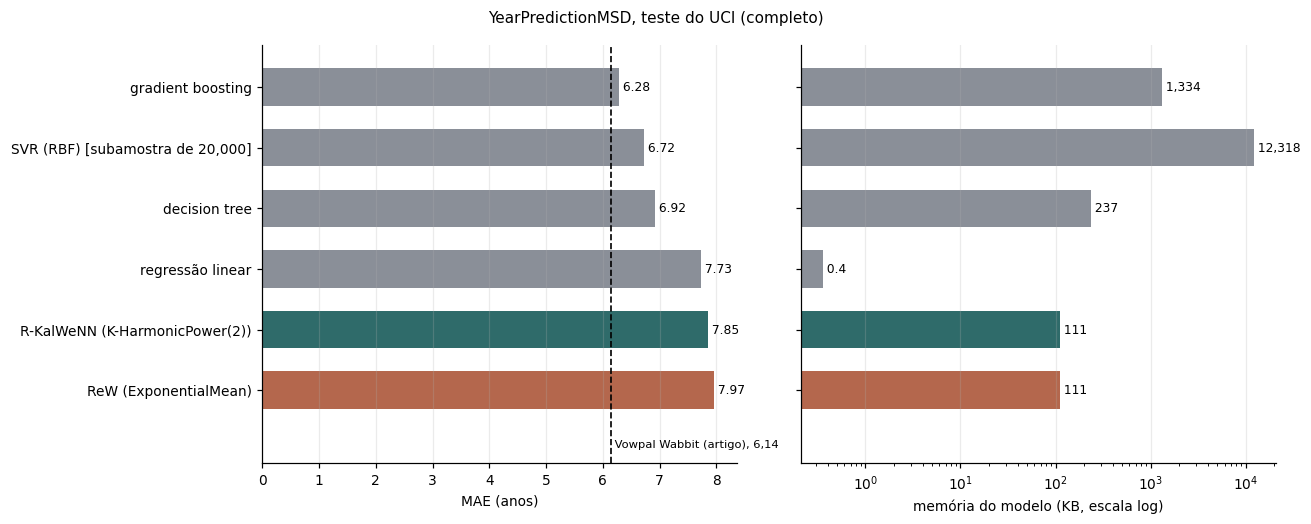

In [85]:
# ═══════════════ COMPARATIVO FINAL: MAE contra memória ══════════════════════
# Memória = bytes dos parâmetros que precisam ficar guardados para predizer.
#
#   ReW e R-KalWeNN   células ocupadas x 24 bytes (chave + 2 campos: a ReW
#                     guarda contador e soma, o R-KalWeNN guarda c e y),
#                     mais o mapping da retina e os limites do thermometer.
#   sklearn           soma dos arrays ajustados de cada modelo.
BYTES_POR_CELULA = 24
# ════════════════════════════════════════════════════════════════════════════

# `bytes_modelo` e a coluna `bytes` do `base_df` vêm da seção 9.

# ── memória dos dois modelos WiSARD, na configuração vencedora ───────────────
_enc_m = build_encoders(X_train, T_V)
_Xb_m  = apply_encoders(X_train, _enc_m)
_ret_m = Retina(A_V, sorteia_mapping(_Xb_m.shape[1], A_V, seed=SEED_MAPPING))
_idx_m = IndiceRK(_ret_m, _ret_m.enderecos(_Xb_m))

mem_mapping = _ret_m.mapping.nbytes
mem_therm   = 2 * N_ATRIB * 8
mem_wisard  = _idx_m.n_celulas * BYTES_POR_CELULA + mem_mapping + mem_therm

print(f"MEMÓRIA DOS MODELOS WISARD  (thermometer {T_V}, address {A_V})\n")
print(f"  células ocupadas          {_idx_m.n_celulas:>12,}")
print(f"  células x {BYTES_POR_CELULA} bytes         {_idx_m.n_celulas*BYTES_POR_CELULA:>12,} bytes")
print(f"  mapping da retina         {mem_mapping:>12,} bytes")
print(f"  limites do thermometer    {mem_therm:>12,} bytes")
print(f"  total                     {mem_wisard:>12,} bytes")
print(f"\n  a ReW e o R-KalWeNN ocupam o mesmo tanto: mesma retina, mesmo treino,")
print(f"  logo o mesmo conjunto de células, e dois campos por célula nos dois")

# ── tabela final ────────────────────────────────────────────────────────────
ref = [(f"ReW ({rew_venc.loc[0,'media']})",        b_rew,          mem_wisard),
       (f"R-KalWeNN ({MELHOR['media']})",          MELHOR["MAE"],  mem_wisard)]
if "base_df" in globals():
    for _, r_ in base_df.iterrows():
        rot = r_["modelo"] + (f" [{r_['obs']}]" if r_["obs"] else "")
        ref.append((rot, r_["MAE"], r_["bytes"]))

comp = (pd.DataFrame(ref, columns=["modelo", "MAE", "bytes"])
        .sort_values("MAE").reset_index(drop=True))
comp["KB"] = comp["bytes"] / 1024

print(f"\n\nMAE E MEMÓRIA  (MODO = {MODO}, teste com {len(y_test):,} exemplos)\n")
print(comp[["modelo", "MAE", "KB"]].to_string(
    index=False, float_format=lambda v: f"{v:,.2f}"))

# ── gráfico ─────────────────────────────────────────────────────────────────
o = comp.iloc[::-1]
cor = [COR_KAL if "R-KalWeNN" in n else COR_REW if n.startswith("ReW") else COR_REF
       for n in o["modelo"]]
fig, ax = plt.subplots(1, 2, figsize=(12, .45 * len(o) + 2.1), sharey=True)

ax[0].barh(np.arange(len(o)), o["MAE"], color=cor, height=.62)
ax[0].axvline(6.14, color="black", ls="--", lw=1.1)
ax[0].text(6.14, -.9, " Vowpal Wabbit (artigo), 6,14", fontsize=7.5, va="center")
ax[0].set(yticks=np.arange(len(o)), yticklabels=o["modelo"],
          xlabel="MAE (anos)", ylim=(-1.2, len(o) - .3))
for i, v in enumerate(o["MAE"]):
    ax[0].text(v, i, f" {v:.2f}", va="center", fontsize=8)

ax[1].barh(np.arange(len(o)), o["KB"], color=cor, height=.62)
ax[1].set_xscale("log")
ax[1].set(xlabel="memória do modelo (KB, escala log)")
for i, v in enumerate(o["KB"]):
    ax[1].text(v, i, f" {v:,.1f}" if v < 10 else f" {v:,.0f}", va="center", fontsize=8)

for a_ in ax:
    a_.grid(axis="y", visible=False)
fig.suptitle(f"YearPredictionMSD, teste do UCI ({MODO})", fontsize=10)
plt.tight_layout(); plt.show()


---
# Seção 11 — Distributive Thermometer

A seção 10 fecha com a ReW e o R-KalWeNN abaixo de chutar a mediana. A seção 8
mostrou por quê: a RAM node mediana tem um endereço que recebe quase todo o
treino, então cada neurônio é praticamente constante.

A causa está no `build_encoders`, que espalha os limiares entre o mínimo e o
máximo de cada atributo. Como os atributos têm cauda longa, o `a2` indo de −337
a 384 com desvio 51 e o `a14` com desvio 1.748, quase todos os limiares caem
onde não há dado, e o bit correspondente nunca muda.

Esta seção troca os limiares por **percentis**, de forma que cada faixa receba
a mesma quantidade de exemplos de treino. É mudança só na codificação: o
modelo, o filtro e as médias ficam iguais.

Isso não é nosso. É o **Distributive Thermometer**, proposto em

> Alan T. L. Bacellar, Zachary Susskind, Luis A. Q. Villon, Igor D. S. Miranda,
> Leandro S. de Araújo, Diego L. C. Dutra, Mauricio Breternitz Jr., Lizy K.
> John, Priscila M. V. Lima, Felipe M. G. França. **Distributive Thermometer: A
> New Unary Encoding for Weightless Neural Networks.** ESANN 2022, European
> Symposium on Artificial Neural Networks, Bruges, p. 31-36.
> https://www.esann.org/sites/default/files/proceedings/2022/ES2022-94.pdf

O artigo divide o treino em B+1 percentis de mesma probabilidade e atribui o
código unário conforme o percentil do dado, que é exatamente o que a classe
abaixo faz. A avaliação deles é só de classificação, com WiSARD e bleaching,
em datasets do UCI cujo maior tem por volta de 19 mil exemplos. O ganho maior
que reportam é no EEG Eye State, de 0,589 para 0,852 de acurácia, o mesmo
fenômeno que aparece aqui.

Duas variantes anteriores da mesma família: o termômetro linear, usado em
Carneiro, França e Lima, *Multilingual part-of-speech tagging with weightless
neural networks*, Neural Networks 66, 2015, e a versão com distribuição
assumida a priori, em Xavier, De Gregorio, França e Lima, *Detection of
elementary particles with the WiSARD n-tuple classifier*, ESANN 2020,
p. 643-648. O levantamento de codificações binárias para WiSARD está em
Kappaun, Camargo, Rangel, Faria, Lima e Oliveira, *Evaluating binary encoding
techniques for WiSARD*, BRACIS 2016, p. 103-108.

O que este notebook acrescenta ao que o artigo mostra: a aplicação à Regression
WiSARD e ao R-KalWeNN, que são regressão e não classificação; a escala de
463.715 exemplos; e a medição de **por que** o termômetro linear falha aqui,
que são os 86,3% de bits constantes e a decomposição de variância abaixo.

**Não treina modelo.** Mede duas coisas por configuração. A primeira é a fração
da variância do ano que fica *entre* as células, que é o teto do que qualquer
ponderação consegue explicar. A segunda é o oráculo: predizer pela média real
de cada célula, sem Kalman e sem média ponderada, o que dá o melhor resultado
possível daquela retina.

O oráculo é medido **no teste**, com as médias aprendidas no treino. Medido no
treino ele melhora sozinho conforme a partição fica mais fina, porque cada
célula passa a guardar um punhado de exemplos, e isso é decoreba e não
capacidade de generalizar. As colunas `vis/cél` e `cobertura` deixam esse
regime visível: visitas por célula perto de 1 e cobertura abaixo de 100% são
sinal de que a partição ficou fina demais para o tamanho do treino.

Se o teto subir e o oráculo no teste descer abaixo dos 7,59 de chutar a
mediana, vale treinar o R-KalWeNN em cima desta codificação. Se não descer, o
limite é o dataset e não a binarização.

Esta é a célula mais pesada do notebook. Com `address` 20 e limiares por
quantil o índice chega a dezenas de milhões de células, e o pico passa de 3 GB.


In [92]:
# ══════════ TESTE: DISTRIBUTIVE THERMOMETER (Bacellar et al., ESANN 2022) ═══
# Não treina o R-KalWeNN. Mede quanta informação sobre o ano a retina consegue
# separar, com os limiares de hoje (mínimo a máximo) e com o Distributive
# Thermometer de Bacellar et al. (ESANN 2022), que põe um limiar por percentil.
#
# O oráculo é medido NO TESTE, com as médias de célula aprendidas no treino.
# Medido no treino ele cresce sozinho conforme a partição fica mais fina, que é
# só decoreba, e não diria nada sobre generalizar.
Q_THERM = T_V              # mesma resolução da configuração vencedora
Q_ADDRS = [A_V, 12, 20]    # address sizes a comparar
# ════════════════════════════════════════════════════════════════════════════


class DistributiveThermometer:
    """Distributive Thermometer, de Bacellar et al. (ESANN 2022).

    Um limiar por percentil em vez de espaçados entre o mínimo e o máximo, de
    forma que cada faixa receba a mesma quantidade de exemplos de treino. Nas
    palavras do artigo, divide o treino em B+1 percentis de mesma probabilidade
    e atribui o código unário conforme o percentil a que o dado pertence.

    Bacellar, Susskind, Villon, Miranda, de Araújo, Dutra, Breternitz Jr.,
    John, Lima e França. Distributive Thermometer: A New Unary Encoding for
    Weightless Neural Networks. ESANN 2022, Bruges, p. 31-36.
    https://www.esann.org/sites/default/files/proceedings/2022/ES2022-94.pdf

    O artigo avalia só classificação, com WiSARD e bleaching, no UCI. Aqui ele
    é aplicado à Regression WiSARD e ao R-KalWeNN.
    """

    def __init__(self, limiares):
        self.limiares = np.asarray(limiares, dtype=float)
        self.resolution = len(self.limiares)

    def encode(self, column):
        return (np.asarray(column, dtype=float)[:, None]
                > self.limiares[None, :]).astype(np.uint8)


def build_encoders_distributivo(X, resolution):
    """`resolution` limiares nos percentis internos, ou seja resolution+1
    faixas de mesma probabilidade, como no artigo."""
    qs = np.linspace(0.0, 100.0, resolution + 2)[1:-1]
    return [DistributiveThermometer(np.percentile(X[:, j], qs))
            for j in range(X.shape[1])]


def diagnostico(nome, Xb_tr, Xb_te, y_tr, y_te, addrs):
    dens = Xb_tr.mean(0)
    const = float(((dens < 0.01) | (dens > 0.99)).mean())
    print(f"\n{nome}")
    print(f"  retina {Xb_tr.shape[1]} bits, densidade {Xb_tr.mean():.3f}, "
          f"bits constantes em >99% do treino: {const*100:.1f}%")
    print(f"  {'addr':>5}{'rams':>6}{'células':>12}{'vis/cél':>9}{'maior end':>11}"
          f"{'entre/total':>13}{'cobertura':>11}{'oráculo MAE':>13}")
    linhas = []
    media_global = float(y_tr.mean())
    for a in addrs:
        ret = Retina(a, sorteia_mapping(Xb_tr.shape[1], a, seed=SEED_MAPPING))
        idx = IndiceRK(ret, ret.enderecos(Xb_tr))
        sl, n = idx.slots_fit, idx.n_celulas
        cont = np.bincount(sl.ravel(), minlength=n).astype(float)
        soma = np.bincount(sl.ravel(), weights=np.repeat(y_tr, ret.n_rams), minlength=n)
        mu = soma / np.where(cont > 0, cont, 1.0)
        entre = float(np.average((mu - media_global) ** 2, weights=cont))

        # oráculo no TESTE: média das células vistas no treino
        sl_te = idx.slots(ret.enderecos(Xb_te))
        ok = sl_te >= 0
        vistos = ok.sum(1)
        soma_mu = np.where(ok, mu[np.where(ok, sl_te, 0)], 0.0).sum(1)
        pred = np.where(vistos > 0, soma_mu / np.maximum(vistos, 1), media_global)
        oraculo = float(np.abs(y_te - pred).mean())

        print(f"  {a:>5}{ret.n_rams:>6}{n:>12,}{cont.mean():>9.0f}"
              f"{cont.max()/len(y_tr)*100:>10.1f}%{entre/y_tr.var():>13.4f}"
              f"{ok.mean()*100:>10.1f}%{oraculo:>13.4f}")
        linhas.append(dict(encoder=nome, addr=a, n_rams=ret.n_rams, celulas=n,
                           visitas_media=cont.mean(),
                           maior_endereco=cont.max()/len(y_tr),
                           entre_total=entre/y_tr.var(), cobertura=float(ok.mean()),
                           oraculo_mae=oraculo))
        del ret, idx, sl, sl_te, ok, cont, soma, mu
    return linhas


print(f"TETO DE INFORMAÇÃO DA RETINA   thermometer {Q_THERM}")
print(f"treino {len(y_train):,}   teste {len(y_test):,}\n")
print(f"  vis/cél      visitas médias por célula ocupada; perto de 1 é decoreba")
print(f"  maior end    fração do treino no endereço mais cheio")
print(f"  entre/total  fração da variância do ano que fica ENTRE células")
print(f"  cobertura    fração dos endereços de teste já vistos no treino")
print(f"  oráculo MAE  média real de cada célula, aplicada AO TESTE, sem filtro")
print(f"\nreferência: chutar a mediana do treino dá MAE "
      f"{np.abs(y_test - np.median(y_train)).mean():.4f} no teste")

res_q = []
for nome, construtor in [("LIMIARES DE HOJE (mínimo a máximo)", build_encoders),
                         ("TERMÔMETRO DISTRIBUTIVO", build_encoders_distributivo)]:
    _enc = construtor(X_train, Q_THERM)
    Xb_tr_q, Xb_te_q = apply_encoders(X_train, _enc), apply_encoders(X_test, _enc)
    res_q += diagnostico(nome, Xb_tr_q, Xb_te_q, y_train, y_test, Q_ADDRS)
    del Xb_tr_q, Xb_te_q, _enc

quantil_df = pd.DataFrame(res_q)
print("\n\nORÁCULO NO TESTE, lado a lado\n")
print(quantil_df.pivot(index="addr", columns="encoder", values="oraculo_mae")
      .to_string(float_format=lambda v: f"{v:,.4f}"))


TETO DE INFORMAÇÃO DA RETINA   thermometer 20
treino 463,715   teste 51,630

  vis/cél      visitas médias por célula ocupada; perto de 1 é decoreba
  maior end    fração do treino no endereço mais cheio
  entre/total  fração da variância do ano que fica ENTRE células
  cobertura    fração dos endereços de teste já vistos no treino
  oráculo MAE  média real de cada célula, aplicada AO TESTE, sem filtro

referência: chutar a mediana do treino dá MAE 7.5878 no teste

LIMIARES DE HOJE (mínimo a máximo)
  retina 1800 bits, densidade 0.410, bits constantes em >99% do treino: 86.3%
   addr  rams     células  vis/cél  maior end  entre/total  cobertura  oráculo MAE
      6   300       4,057    34290     100.0%       0.0024     100.0%       8.0903
     12   150       7,410     9387     100.0%       0.0050     100.0%       8.0666
     20    90      13,545     3081      99.6%       0.0084     100.0%       8.0370

TERMÔMETRO DISTRIBUTIVO
  retina 1800 bits, densidade 0.500, bits constantes em >99%

---
# Seção 12 — R-KalWeNN sobre o Distributive Thermometer

A seção 11 mostrou que o Distributive Thermometer de Bacellar et al. tira os
86,3% de bits constantes e sobe o teto de informação da retina de 0,0084 para
0,1955. Esta seção treina o R-KalWeNN em cima dessa codificação, que é a única
mudança em relação à seção 6.

**As faixas do Kalman vêm da medição da seção 11**, não de chute. O `r_y` é a
variância do ano dentro das células, que ficou entre 96 e 114, e o `p0_y` é a
variância entre as células, que ficou entre 5,6 e 23. Como só as razões `p0/r`
e `q/r` importam, o `r` fica fixo e a varredura anda em `p0` e `q`. O `p0_y`
varre de 5, que é o valor calibrado, até 500, que é o regime de confiar no dado
e ignorar o prior.

Os dois address sizes escolhidos são 12 e 20, que na seção 11 foram os que
deram teto maior sem a cobertura do teste desabar.

**O que esperar.** O oráculo da seção 11, que é o melhor possível daquela
retina, ficou em 7,5728 contra 7,5878 de chutar a mediana, uma diferença de
0,015 ano com erro padrão de 0,037. Ou seja, o teto empata com a constante. O
modelo pode ficar um pouco acima do oráculo, porque o oráculo usa média simples
enquanto o R-KalWeNN pondera pela confiança e desconta as células de uma visita
só, e num teste em escala menor foi o que aconteceu. Mas não há espaço para
chegar perto dos 6,28 do gradient boosting.

O `Q12_THERM` aceita lista, então o tamanho do termômetro entra no grid junto
do address size. Com quantis todo bit é informativo, ao contrário do mín-máx
onde 86% eram constantes, então mais bits significa quantis mais finos: pode
ajudar em address baixo e atrapalhar em address alto, onde as células já ficam
com poucas visitas.

A memória do modelo é registrada por par (thermometer, address), como células
ocupadas vezes 24 bytes mais o mapping e os limiares, e a seção 13 usa isso.


In [93]:
# ═══════════ R-KalWeNN SOBRE O DISTRIBUTIVE THERMOMETER (ESANN 2022) ════════
# Faixas do Kalman derivadas da decomposição de variância da seção 11:
#   r_y  = variância DENTRO das células, que ficou em 96 (addr 20) a 114 (addr 12)
#   p0_y = variância ENTRE  as  células, que ficou em  23 (addr 20) a   5,6 (addr 12)
# Só as razões p0/r e q/r importam, então r fica fixo e varre-se p0 e q.
Q12_THERM = [20]
Q12_ADDR  = [6, 12, 20]

Q12_R_C   = 1.0
Q12_P0_C  = [0.1, 1.0]              # c espalhado na faixa de visitas de cada addr
Q12_Q_C   = [1e-6, 1e-2]

Q12_R_Y   = 100.0
Q12_P0_Y  = [5.0, 20.0, 100.0, 500.0]   # p0/r de 0,05 (calibrado) a 5
Q12_Q_Y   = [0.001, 1.0, 10.0]

Q12_MEDIAS = ["K-SimpleMean", "K-PowerMean(2)", "K-HarmonicMean",
              "K-HarmonicPower(2)", "K-ExponentialMean", "K-Median"]
Q12_SEEDS  = (0,)
Q12_RODAR_REW = True                # a ReW no ponto vencedor, para comparar
Q12_ARQ = "grid_quantil.csv"
# ════════════════════════════════════════════════════════════════════════════

assert "build_encoders_distributivo" in globals(), "rode a seção 11 antes desta"

# ── libera as retinas das seções anteriores ─────────────────────────────────
# Cada uma é (n_treino x 1800) uint8, ou seja 0,83 GB com o treino completo, e
# elas ficam vivas no kernel depois que a célula que as criou termina. Somadas
# passam de 3 GB e não são mais usadas daqui pra frente. Os resultados
# (MELHOR, rew_venc, b_rew, base_df, quantil_df) não são tocados.
import gc, resource
_antes = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e9
for _n in ("Xb", "Xb_tr", "Xb_te", "Xb_tr_v", "Xb_te_v", "Xb_a", "_Xb_m",
           "Xb_tr_q", "Xb_te_q", "IDX", "SLOTS_TE", "_idx_m", "_ret_m", "_enc_m",
           "addr", "sl", "idx", "ret"):
    if _n in globals():
        del globals()[_n]
_liberou = gc.collect()
print(f"pico de memória do kernel até aqui: {_antes:.2f} GB")
print(f"retinas antigas liberadas, {_liberou} objetos coletados\n")

_combos12 = list(product(Q12_P0_C, Q12_Q_C, Q12_P0_Y, Q12_Q_Y))
X0_Y_12 = float(np.median(y_train))
print(f"BUSCA  thermometer {Q12_THERM}, limiares por quantil, "
      f"address {Q12_ADDR}, x0_y {X0_Y_12:.0f}")
print(f"  {len(_combos12)} combinações x {len(Q12_ADDR)} address x "
      f"{len(Q12_SEEDS)} seed = {len(_combos12)*len(Q12_ADDR)*len(Q12_SEEDS)} ajustes")
print(f"  as {len(Q12_MEDIAS)} médias saem do mesmo ajuste\n")

print("esta seção vai alocar, por tamanho de termômetro:")
for _t in Q12_THERM:
    _b = _t * X_train.shape[1]
    print(f"  therm {_t:<3} retina do treino {len(X_train)*_b/1e9:>5.2f} GB, "
          f"do teste {len(X_test)*_b/1e9:>5.2f} GB, maior slots "
          f"{len(X_train)*(_b//min(Q12_ADDR))*4/1e9:>5.2f} GB")
print()

linhas12, t0 = [], time.perf_counter()
for T in Q12_THERM:
    _enc12 = build_encoders_distributivo(X_train, T)
    Xb_tr12 = apply_encoders(X_train, _enc12)
    Xb_te12 = apply_encoders(X_test, _enc12)
    print(f"\nthermometer {T}: retina {Xb_tr12.shape[1]} bits, "
          f"densidade {Xb_tr12.mean():.3f}")
    for a in Q12_ADDR:
        ret = Retina(a, sorteia_mapping(Xb_tr12.shape[1], a, seed=SEED_MAPPING))
        idx = IndiceRK(ret, ret.enderecos(Xb_tr12))
        sl_te = idx.slots(ret.enderecos(Xb_te12))
        # memória do modelo: células x (chave + c + y), mapping e limiares
        mem = idx.n_celulas * 24 + ret.mapping.nbytes + 2 * X_train.shape[1] * 8
        print(f"  address {a:>2}: {ret.n_rams:>4} RAM nodes, {idx.n_celulas:>10,} células, "
              f"cobertura {(sl_te >= 0).mean()*100:>5.1f}%, memória {mem/1024:>10,.0f} KB")
        for p0c, qc, p0y, qy in _combos12:
            acum = {m: [] for m in Q12_MEDIAS}
            for s in Q12_SEEDS:
                mod = RKalWeNN(a, ret.mapping.ravel(), q_c=qc, r_c=Q12_R_C, p0_c=p0c,
                               q_y=qy, r_y=Q12_R_Y, p0_y=p0y, x0_c=0.0, x0_y=X0_Y_12,
                               seed=s, indice=idx).fit(y=y_train)
                for nome, v in avalia(mod, sl_te, y_test, Q12_MEDIAS).items():
                    acum[nome].append(v)
            for nome, vs in acum.items():
                arr = np.array([v[:3] for v in vs], dtype=float)
                linhas12.append(dict(therm=T, address=a, n_rams=ret.n_rams,
                                     celulas=idx.n_celulas, memoria_bytes=mem,
                                     media=nome, p0_c=p0c, q_c=qc, p0_y=p0y, q_y=qy,
                                     MAE=arr[:, 0].mean(), RMSE=arr[:, 1].mean(),
                                     R2=arr[:, 2].mean(),
                                     nao_finito=int(max(v[3] for v in vs))))
        del ret, idx, sl_te
    print(f"  parcial: {(time.perf_counter()-t0)/60:.1f} min")
    if T != Q12_THERM[-1]:
        del Xb_tr12, Xb_te12, _enc12
        gc.collect()

grid12 = pd.DataFrame(linhas12).sort_values("MAE").reset_index(drop=True)
grid12.to_csv(Q12_ARQ, index=False)
M12 = grid12.loc[0].to_dict()
print(f"concluído em {(time.perf_counter()-t0)/60:.1f} min, "
      f"{len(grid12):,} linhas em {Q12_ARQ}\n")
print("AS 10 MELHORES\n")
print(grid12.head(10)[["therm", "address", "media", "p0_c", "q_c", "p0_y", "q_y", "MAE", "R2"]]
      .to_string(index=False, float_format=lambda v: f"{v:.4g}"))
print(f"\nmelhor por (therm, address):")
print(grid12.groupby(["therm","address"]).MAE.min().to_string(float_format=lambda v: f"{v:.4f}"))
print(f"\nmelhor por média:")
print(grid12.groupby("media").MAE.min().sort_values().to_string(float_format=lambda v: f"{v:.4f}"))

# ── a ReW no mesmo ponto ────────────────────────────────────────────────────
A12, T12 = int(M12["address"]), int(M12["therm"])
b_rew12 = np.nan
if Q12_RODAR_REW:
    print(f"\n\nReW no ponto vencedor (therm {T12}, address {A12}), Python puro\n")
    if Xb_tr12.shape[1] != T12 * X_train.shape[1]:
        _e = build_encoders_distributivo(X_train, T12)
        Xb_tr12, Xb_te12 = apply_encoders(X_train, _e), apply_encoders(X_test, _e)
    ret12 = Retina(A12, sorteia_mapping(Xb_tr12.shape[1], A12, seed=SEED_MAPPING))
    ss = float(np.sum((y_test - y_test.mean()) ** 2))
    lr = []
    for nome, m in medias_rew().items():
        t1 = time.perf_counter()
        pr = RegressionWiSARD(A12, m, ret12.mapping.ravel()).fit(Xb_tr12, y_train).predict(Xb_te12)
        nf = int((~np.isfinite(pr)).sum())
        if nf:
            bons = pr[np.isfinite(pr)]
            pr = np.where(np.isfinite(pr), pr, bons.mean() if len(bons) else 0.0)
        lr.append({"media": nome, "MAE": mean_absolute_error(y_test, pr),
                   "R2": 1.0 - float(np.sum((y_test - pr) ** 2)) / ss, "nao_finito": nf})
        print(f"  {nome:<18} MAE {lr[-1]['MAE']:>7.4f}   ({time.perf_counter()-t1:.0f} s)")
    rew12 = pd.DataFrame(lr).sort_values("MAE").reset_index(drop=True)
    b_rew12 = float(rew12.MAE.min())

# ── fechamento ──────────────────────────────────────────────────────────────
print(f"\n\nONDE ISSO CHEGOU, teste do UCI com {len(y_test):,} exemplos\n")
fecha = [("Vowpal Wabbit (artigo)", 6.14),
         ("gradient boosting (seção 9)", float(base_df.MAE.min())),
         ("chutar a mediana do treino", float(np.abs(y_test - np.median(y_train)).mean())),
         ("oráculo da retina distributiva (seção 11)",
          float(quantil_df[quantil_df.encoder.str.contains("DISTRIBUTIV|QUANTIL")]
                .oraculo_mae.min())),
         (f"R-KalWeNN distributivo ({M12['media']}, therm {T12} address {A12})", float(M12["MAE"])),
         ("R-KalWeNN mín-máx (seção 6)", float(MELHOR["MAE"])),
         ("ReW mín-máx (seção 7)", float(b_rew))]
if Q12_RODAR_REW:
    fecha.append((f"ReW distributivo (therm {T12} address {A12})", b_rew12))
for nome, v in sorted(fecha, key=lambda t: t[1]):
    print(f"  {nome:<44}{v:>8.4f}")


pico de memória do kernel até aqui: 3.83 GB
retinas antigas liberadas, 34969 objetos coletados

BUSCA  thermometer [20], limiares por quantil, address [6, 12, 20], x0_y 2002
  48 combinações x 3 address x 1 seed = 144 ajustes
  as 6 médias saem do mesmo ajuste

esta seção vai alocar, por tamanho de termômetro:
  therm 20  retina do treino  0.83 GB, do teste  0.09 GB, maior slots  0.56 GB


thermometer 20: retina 1800 bits, densidade 0.500
  address  6:  300 RAM nodes,     18,473 células, cobertura 100.0%, memória        448 KB
  address 12:  150 RAM nodes,    405,859 células, cobertura  99.9%, memória      9,528 KB
  address 20:   90 RAM nodes,  5,607,473 células, cobertura  93.3%, memória    131,441 KB
  parcial: 78.5 min
concluído em 78.5 min, 864 linhas em grid_quantil.csv

AS 10 MELHORES

 therm  address             media  p0_c   q_c  p0_y   q_y   MAE       R2
    20       20 K-ExponentialMean   0.1  0.01   100 0.001 7.285 -0.01713
    20       20 K-ExponentialMean   0.1 1e-06   10

---
# Seção 13 — Como os hiperparâmetros se comportam

Três blocos de gráfico sobre a varredura da seção 12.

**Por hiperparâmetro.** Um painel por eixo. Cada ponto claro é uma configuração
rodada, e a linha escura liga o melhor MAE de cada nível. A linha responde até
onde dá para chegar com aquele valor, e a nuvem em volta mostra o quanto o
resto do grid ainda mexe no resultado. A linha tracejada é chutar a mediana do
treino. Um eixo em que a linha escura é plana não está decidindo nada.

**Codificação contra memória.** O tamanho do termômetro e o address size são as
duas escolhas que mudam quanto o modelo ocupa. O primeiro painel mostra o erro,
o segundo a memória, e o terceiro põe os dois juntos: quanto se paga em bytes
por cada ano de MAE. A memória é a mesma conta da seção 10, células ocupadas
vezes 24 bytes mais o mapping da retina e os limiares do termômetro.

**Endereços e acessos.** A mesma análise da seção 8, agora sobre o termômetro
distributivo e na configuração vencedora, para ver se a distribuição de acessos
deixou de ser concentrada. Os eixos de visita estão em escala log porque a
distribuição vai de 1 a milhares.


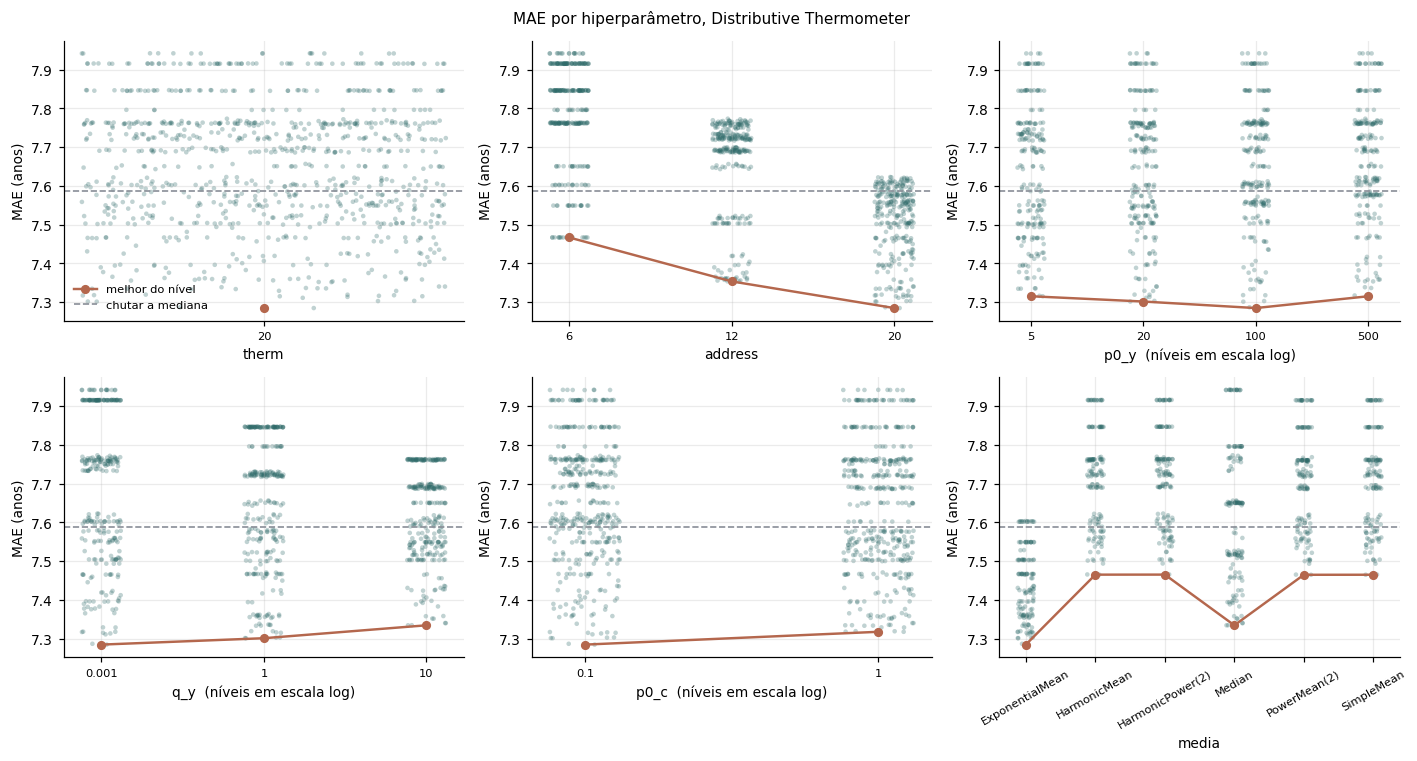

MELHOR MAE E MEMÓRIA POR CODIFICAÇÃO

 therm  address  n_rams  celulas         KB  MAE
    20        6     300    18473     448.43 7.47
    20       12     150   405859   9,527.79 7.35
    20       20      90  5607473 131,440.62 7.28


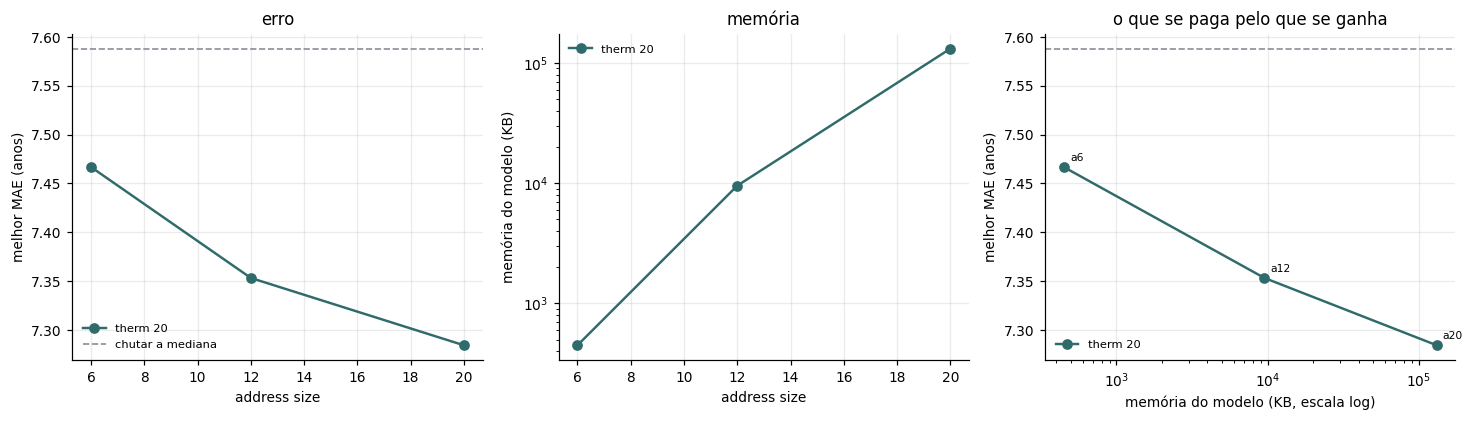

In [94]:
# ═══════════════ COMO CADA HIPERPARÂMETRO SE COMPORTA ═══════════════════════
# Cada painel: um ponto claro por configuração rodada, e a linha escura ligando
# o MELHOR MAE de cada nível. A linha responde "até onde dá para chegar com
# este valor", e a nuvem mostra o quanto o resto do grid mexe no resultado.
EIXOS13 = ["therm", "address", "p0_y", "q_y", "p0_c", "media"]
LOG13   = {"p0_y", "q_y", "p0_c"}      # eixos que andam em ordem de grandeza
# ════════════════════════════════════════════════════════════════════════════

if "grid12" not in globals():
    grid12 = pd.read_csv(Q12_ARQ).sort_values("MAE").reset_index(drop=True)

_ref13 = float(np.abs(y_test - np.median(y_train)).mean())
fig, ax = plt.subplots(2, 3, figsize=(13, 7))
for a_, col in zip(ax.ravel(), EIXOS13):
    niveis = sorted(grid12[col].unique(), key=lambda v: (isinstance(v, str), v))
    pos = {v: i for i, v in enumerate(niveis)}
    x = grid12[col].map(pos).values
    a_.scatter(x + np.random.default_rng(0).uniform(-.12, .12, len(x)),
               grid12["MAE"], s=9, alpha=.30, color=COR_KAL, edgecolor="none")
    melhor = [grid12.loc[grid12[col] == v, "MAE"].min() for v in niveis]
    a_.plot(range(len(niveis)), melhor, "o-", color=COR_REW, lw=1.6, ms=5,
            label="melhor do nível")
    a_.axhline(_ref13, color=COR_REF, ls="--", lw=1.1, label="chutar a mediana")
    rot = [f"{v:g}" if not isinstance(v, str) else v.replace("K-", "") for v in niveis]
    a_.set(xticks=range(len(niveis)), xticklabels=rot, xlabel=col, ylabel="MAE (anos)")
    a_.tick_params(axis="x", labelrotation=30 if col == "media" else 0, labelsize=7.5)
    if col in LOG13:
        a_.set_xlabel(f"{col}  (níveis em escala log)")
ax[0, 0].legend(frameon=False, fontsize=7.5)
fig.suptitle("MAE por hiperparâmetro, Distributive Thermometer", fontsize=10)
plt.tight_layout(); plt.show()


# ═══════════════ CODIFICAÇÃO: MAE CONTRA MEMÓRIA ════════════════════════════
por_par = (grid12.groupby(["therm", "address"])
           .agg(MAE=("MAE", "min"), memoria_bytes=("memoria_bytes", "first"),
                celulas=("celulas", "first"), n_rams=("n_rams", "first"))
           .reset_index())
por_par["KB"] = por_par.memoria_bytes / 1024
print("MELHOR MAE E MEMÓRIA POR CODIFICAÇÃO\n")
print(por_par[["therm", "address", "n_rams", "celulas", "KB", "MAE"]]
      .to_string(index=False, float_format=lambda v: f"{v:,.2f}"))

fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.9))
cores13 = [COR_KAL, COR_REW, "#6B7A8F", "#A8894C"]

for i, t_ in enumerate(sorted(por_par.therm.unique())):
    s = por_par[por_par.therm == t_].sort_values("address")
    c = cores13[i % len(cores13)]
    ax[0].plot(s.address, s.MAE, "o-", color=c, lw=1.6, ms=6, label=f"therm {t_}")
    ax[1].plot(s.address, s.KB, "o-", color=c, lw=1.6, ms=6, label=f"therm {t_}")
    ax[2].plot(s.KB, s.MAE, "o-", color=c, lw=1.6, ms=6, label=f"therm {t_}")
    for _, r_ in s.iterrows():
        ax[2].annotate(f"a{int(r_.address)}", (r_.KB, r_.MAE), fontsize=7,
                       xytext=(4, 4), textcoords="offset points")

ax[0].axhline(_ref13, color=COR_REF, ls="--", lw=1.1, label="chutar a mediana")
ax[0].set(xlabel="address size", ylabel="melhor MAE (anos)", title="erro")
ax[1].set(xlabel="address size", ylabel="memória do modelo (KB)", yscale="log",
          title="memória")
ax[2].axhline(_ref13, color=COR_REF, ls="--", lw=1.1)
ax[2].set(xlabel="memória do modelo (KB, escala log)", xscale="log",
          ylabel="melhor MAE (anos)", title="o que se paga pelo que se ganha")
for a_ in ax:
    a_.legend(frameon=False, fontsize=7.5)
plt.tight_layout(); plt.show()


thermometer 20 distributivo, address 20  ->  90 RAM nodes, 1,048,576 endereços possíveis por RAM node
463,715 exemplos de treino

ENDEREÇOS OCUPADOS POR RAM NODE

  mínimo 28079   mediana 61741   máximo 110719   média 62305.3
  de 1,048,576 possíveis, ou seja 5.94% em média
  total de células ocupadas: 5,607,473

VISITAS POR ENDEREÇO OCUPADO

  mínimo 1   mediana 2   máximo 34,653   média 7.4
  endereços com 1 visita só: 48.0%
  endereços com 2 ou mais  : 52.0%

CONCENTRAÇÃO

  o RAM node mais concentrado tem um endereço com 34,653 dos 463,715 exemplos (7.5%)
  o mais espalhado tem no máximo 559 num mesmo endereço (0.1%)
  mediana, entre as RAM nodes, do endereço mais cheio: 0.6% dos exemplos


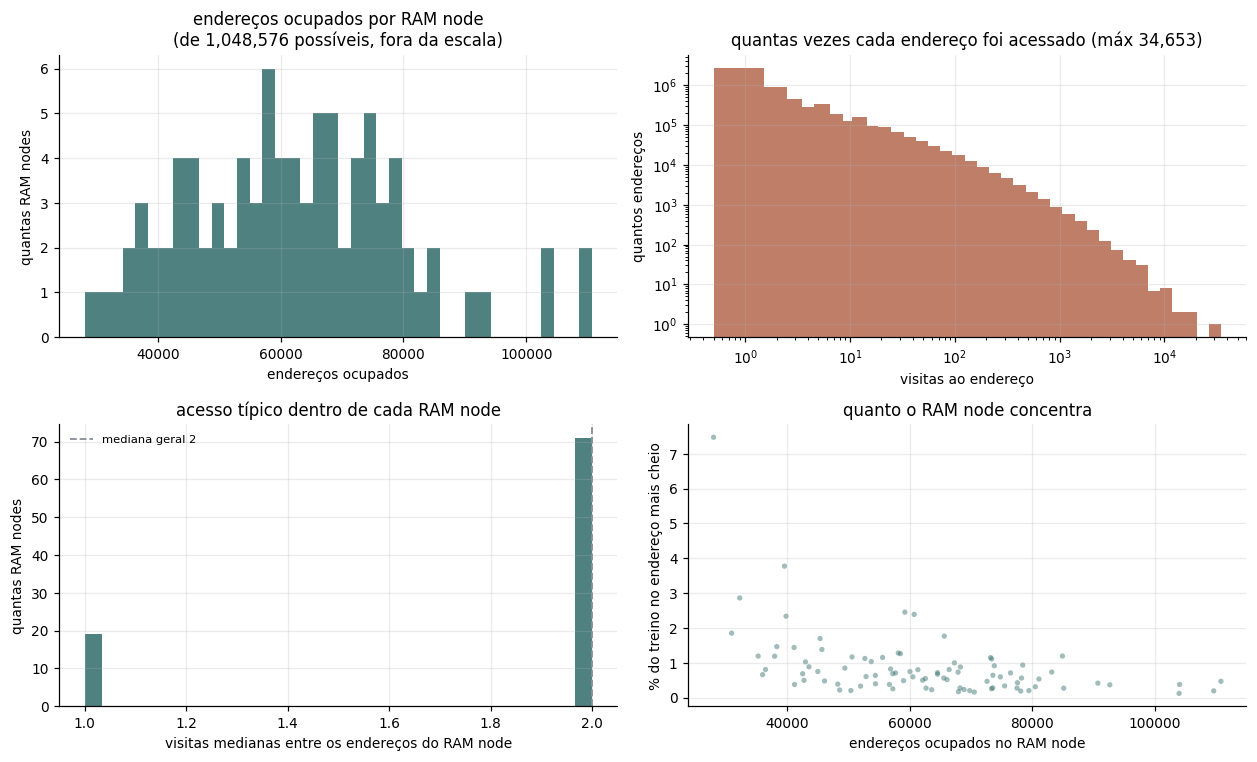

In [95]:
# ═══════════════ ENDEREÇOS E ACESSOS NA CONFIGURAÇÃO VENCEDORA ══════════════
T_B = int(M12["therm"]) if "M12" in globals() else int(grid12.loc[0, "therm"])
A_B = int(M12["address"]) if "M12" in globals() else int(grid12.loc[0, "address"])
# ════════════════════════════════════════════════════════════════════════════

Xb_b = apply_encoders(X_train, build_encoders_distributivo(X_train, T_B))
ret_b = Retina(A_B, sorteia_mapping(Xb_b.shape[1], A_B, seed=SEED_MAPPING))
addr_b = ret_b.enderecos(Xb_b)

ocup_b, visitas_b = [], []
for r_ in range(ret_b.n_rams):
    _, c_ = np.unique(addr_b[:, r_], return_counts=True)
    ocup_b.append(len(c_)); visitas_b.append(c_)
ocup_b = np.array(ocup_b)
todas_b = np.concatenate(visitas_b)
max_b = np.array([v.max() for v in visitas_b])
med_b = np.array([np.median(v) for v in visitas_b])

print(f"thermometer {T_B} distributivo, address {A_B}  ->  {ret_b.n_rams} RAM nodes, "
      f"{ret_b.n_addr:,} endereços possíveis por RAM node")
print(f"{len(X_train):,} exemplos de treino\n")
print("ENDEREÇOS OCUPADOS POR RAM NODE\n")
print(f"  mínimo {ocup_b.min()}   mediana {int(np.median(ocup_b))}   "
      f"máximo {ocup_b.max()}   média {ocup_b.mean():.1f}")
print(f"  de {ret_b.n_addr:,} possíveis, ou seja "
      f"{100*ocup_b.mean()/ret_b.n_addr:.2f}% em média")
print(f"  total de células ocupadas: {ocup_b.sum():,}")
print("\nVISITAS POR ENDEREÇO OCUPADO\n")
print(f"  mínimo {todas_b.min()}   mediana {int(np.median(todas_b))}   "
      f"máximo {todas_b.max():,}   média {todas_b.mean():.1f}")
print(f"  endereços com 1 visita só: {100*(todas_b==1).mean():.1f}%")
print(f"  endereços com 2 ou mais  : {100*(todas_b>=2).mean():.1f}%")
print("\nCONCENTRAÇÃO\n")
print(f"  o RAM node mais concentrado tem um endereço com {max_b.max():,} "
      f"dos {len(X_train):,} exemplos ({100*max_b.max()/len(X_train):.1f}%)")
print(f"  o mais espalhado tem no máximo {max_b.min():,} num mesmo endereço "
      f"({100*max_b.min()/len(X_train):.1f}%)")
print(f"  mediana, entre as RAM nodes, do endereço mais cheio: "
      f"{100*np.median(max_b)/len(X_train):.1f}% dos exemplos")

def _bins_log(v, n=40):
    """Bins espaçados em log, para distribuições que vão de 1 a milhares."""
    hi = max(int(v.max()), 2)
    return np.unique(np.round(np.geomspace(1, hi, n)).astype(int)) - 0.5

fig, ax = plt.subplots(2, 2, figsize=(11.5, 7))

ax[0, 0].hist(ocup_b, bins=40, color=COR_KAL, alpha=.85)
if ret_b.n_addr <= 3 * ocup_b.max():
    ax[0, 0].axvline(ret_b.n_addr, color=COR_REF, ls="--", lw=1.2,
                     label=f"possíveis ({ret_b.n_addr:,})")
    ax[0, 0].legend(frameon=False, fontsize=7.5)
    _tit = "endereços ocupados por RAM node"
else:
    _tit = (f"endereços ocupados por RAM node\n"
            f"(de {ret_b.n_addr:,} possíveis, fora da escala)")
ax[0, 0].set(xlabel="endereços ocupados", ylabel="quantas RAM nodes", title=_tit)

ax[0, 1].hist(todas_b, bins=_bins_log(todas_b), color=COR_REW, alpha=.85)
ax[0, 1].set(xlabel="visitas ao endereço", ylabel="quantos endereços",
             xscale="log", yscale="log",
             title=f"quantas vezes cada endereço foi acessado (máx {todas_b.max():,})")

if med_b.min() == med_b.max():
    ax[1, 0].hist(todas_b[todas_b <= np.percentile(todas_b, 95)],
                  bins=_bins_log(todas_b[todas_b <= np.percentile(todas_b, 95)], 25),
                  color=COR_KAL, alpha=.85)
    ax[1, 0].set(xlabel="visitas ao endereço", ylabel="quantos endereços", xscale="log",
                 title=f"os 95% menos acessados\n(a mediana de toda RAM node é "
                       f"{med_b.min():,.0f}, por isso o painel muda)")
else:
    ax[1, 0].hist(med_b, bins=30, color=COR_KAL, alpha=.85)
    ax[1, 0].axvline(np.median(med_b), color=COR_REF, ls="--", lw=1.2,
                     label=f"mediana geral {np.median(med_b):,.0f}")
    ax[1, 0].set(xlabel="visitas medianas entre os endereços do RAM node",
                 ylabel="quantas RAM nodes", title="acesso típico dentro de cada RAM node")
    ax[1, 0].legend(frameon=False, fontsize=7.5)

ax[1, 1].scatter(ocup_b, 100 * max_b / len(X_train), s=12, alpha=.45, color=COR_KAL,
                 edgecolor="none")
ax[1, 1].set(xlabel="endereços ocupados no RAM node",
             ylabel="% do treino no endereço mais cheio",
             title="quanto o RAM node concentra")
plt.tight_layout(); plt.show()
